# 🐦 Twitter Sentiment Analysis
## Analyse de sentiment des tweets des compagnies aériennes américaines

**Dataset :** [Twitter US Airline Sentiment](https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment/data) — 14 640 tweets, 6 compagnies, du 16 au 24 février 2015.

**Objectif :** prédire le sentiment d'un tweet (`negative`, `neutral`, `positive`) à partir de son texte, avec un pipeline complet, mesuré et interprété :

| Étape | Contenu |
|---|---|
| 1. Exploration | qualité des données, distribution de la cible, compagnies, motifs de plainte, temporalité, longueur, vocabulaire |
| 2. Feature engineering | nettoyage NLP, 22 variables linguistiques et lexicales (dont VADER), TF-IDF mots **et** caractères, sélection χ² |
| 3. Modélisation | Naive Bayes, SVM linéaire, régression logistique, forêt aléatoire, réglage des hyperparamètres |
| 4. Résultats | validation croisée, jeu de test, ablation des features, matrices de confusion, coefficients, analyse d'erreurs |

## 0. Sommaire

1. **Contexte et problématique** — pourquoi ce corpus, quelles difficultés
2. **Environnement de travail** — bibliothèques, graines, style
3. **Chargement des données** — lecture, dates, doublons
4. **Analyse exploratoire (EDA)** — 4.1 qualité · 4.2 cible · 4.3 compagnies · 4.4 motifs · 4.5 temporalité · 4.6 longueur et viralité · 4.7 géographie · 4.8 vocabulaire
5. **Feature engineering** — 5.1 stratégie · 5.2 nettoyage · 5.3 variables créées · 5.4 analyse des variables · 5.5 découpage train/test · 5.6 TF-IDF et χ²
6. **Modélisation et résultats** — 6.1 matrices · 6.2 protocole · 6.3 comparaison · 6.4 analyse détaillée · 6.5 ablation · 6.6 réglage · 6.7 coefficients · 6.8 erreurs · 6.9 prédiction
7. **Sauvegarde du modèle**
8. **Conclusion, limites et perspectives**

# 1. Contexte et problématique

Les compagnies aériennes reçoivent chaque jour des milliers de messages publics sur Twitter : plaintes pour retard, bagages perdus, félicitations pour un équipage. **Classer automatiquement ces messages** permet de router les réclamations, de mesurer la satisfaction en continu et de détecter les incidents opérationnels.

**Problématique :** à partir du seul texte d'un tweet (≤ 140 caractères, mentions, hashtags, fautes, ironie), prédire l'étiquette `negative`, `neutral` ou `positive`.

Trois difficultés structurent la démarche :

1. **Déséquilibre des classes** — les tweets négatifs représentent 62,7 % du corpus. Un modèle qui prédit toujours « negative » atteint donc 62,7 % d'*accuracy* sans rien apprendre : c'est pourquoi le **F1-score macro** (moyenne non pondérée des F1 par classe) sera la métrique de référence, complétée par le rappel de chaque classe.
2. **Labels bruités** — les étiquettes viennent d'une annotation par foule (CrowdFlower) avec un score de confiance (moyenne 0,90 ; 236 tweets sous 0,50). Un tweet « positif » du type *« @united This is probably the least dependable… »* est en réalité une plainte : le plafond de performance est donc limité par la qualité des labels.
3. **Langage Twitter** — abréviations, sarcasme, négations (`not good` ≠ `good`), ponctuation expressive, mentions `@compagnie`. Le nettoyage et les features doivent en tenir compte.

**Fil conducteur du notebook :** mesurer d'abord ce que valent les données (EDA), construire des représentations utiles (feature engineering), comparer honnêtement les modèles (validation croisée + test tenu à l'écart), puis **expliquer** les résultats (ablation, coefficients, erreurs).

# 2. Environnement de travail

On fixe les graines aléatoires, on télécharge les ressources NLTK (stopwords, WordNet, lexique VADER) et on uniformise le style des graphiques.

In [1]:
# --- Bibliothèques standard ---
import html
import os
import re
import time
import warnings
from collections import Counter
from functools import lru_cache
from pathlib import Path

warnings.filterwarnings("ignore")

# --- Données et calcul ---
import numpy as np
import pandas as pd
import scipy.sparse as sp

# --- Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from matplotlib.colors import ListedColormap

# --- NLP ---
import nltk

for _pkg in ("stopwords", "wordnet", "vader_lexicon", "omw-1.4"):
    try:
        nltk.download(_pkg, quiet=True)
    except Exception:  # mode hors-ligne : les ressources sont peut-être déjà présentes
        pass

from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.stem import WordNetLemmatizer

# --- Scikit-learn ---
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import chi2, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import LinearSVC

# --- Reproductibilité ---
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Style des graphiques ---
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid.axis": "y",
})
PALETTE = {"negative": "#d1495b", "neutral": "#8d99ae", "positive": "#2a9d8f"}
ORDER = ["negative", "neutral", "positive"]
LABEL_MAP = {0: "negative", 1: "neutral", 2: "positive"}

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

import matplotlib
import sklearn

print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} "
      f"| matplotlib {matplotlib.__version__} | nltk {nltk.__version__}")

pandas 2.1.4 | numpy 1.26.4 | scikit-learn 1.4.2 | matplotlib 3.8.3 | nltk 3.10.4


# 3. Chargement des données

Le fichier `dataset.csv` doit se trouver **dans le même dossier que le notebook** (il est téléchargeable sur Kaggle via le lien ci-dessus). On convertit la date, puis on supprime les doublons stricts.

In [2]:
DATA_PATH = Path("dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "dataset.csv introuvable : placez le fichier Kaggle 'Twitter US Airline Sentiment' "
        "à côté du notebook, puis relancez cette cellule."
    )

df = pd.read_csv(DATA_PATH)
df["tweet_created"] = pd.to_datetime(df["tweet_created"], utc=True, errors="coerce")
df["tweet_local"] = df["tweet_created"].dt.tz_convert("America/Los_Angeles")

n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dimensions : {df.shape[0]} lignes x {df.shape[1] - 1} colonnes d'origine")
print(f"Doublons stricts supprimés : {n_before - len(df)}")
print(f"Période couverte : {df['tweet_local'].min():%d/%m/%Y %H:%M} -> {df['tweet_local'].max():%d/%m/%Y %H:%M} (heure du Pacifique)")

df.head(3)

Dimensions : 14604 lignes x 15 colonnes d'origine
Doublons stricts supprimés : 36
Période couverte : 16/02/2015 23:36 -> 24/02/2015 11:53 (heure du Pacifique)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone,tweet_local
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 19:35:52+00:00,NaN,Eastern Time (US & Canada),2015-02-24 11:35:52-08:00
1,570301130888122368,positive,0.3486,NaN,0.0,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials to the experience... tacky.,NaN,2015-02-24 19:15:59+00:00,NaN,Pacific Time (US & Canada),2015-02-24 11:15:59-08:00
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I need to take another trip!,NaN,2015-02-24 19:15:48+00:00,Lets Play,Central Time (US & Canada),2015-02-24 11:15:48-08:00


**Lecture.** 14 640 tweets initiaux, 15 colonnes : l'identifiant, l'étiquette et sa confiance, le motif de plainte, la compagnie, le texte, et des métadonnées de profil (nom, localisation, fuseau horaire) ainsi que la date. Les 36 doublons stricts (mêmes valeurs sur toutes les colonnes) sont des copies techniques, on les retire pour ne pas avantager artificiellement le modèle ; les 213 textes identiques restants sont conservés car ils peuvent correspondre à de vrais retweets.

Les colonnes utiles au modèle sont peu nombreuses : **`text`** (la seule information disponible au moment de la prédiction) et **`airline_sentiment`** (la cible). Les autres servent à l'analyse ou seront écartées.

# 4. Analyse exploratoire (EDA)

Objectif : comprendre la structure du corpus avant de modéliser, et repérer les pièges (valeurs manquantes structurées, déséquilibre, biais de collecte).

## 4.1 Qualité des données

On inventorie types, valeurs manquantes et cardinalité de chaque colonne.

In [3]:
quality = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "manquants": df.isna().sum(),
    "manquants_%": (df.isna().mean() * 100).round(1),
    "valeurs_uniques": df.nunique(),
})
quality["exemple"] = [
    (str(df[c].dropna().iloc[0])[:40] if df[c].notna().any() else "—") for c in df.columns
]
quality.sort_values("manquants_%", ascending=False)

,type,non_null,manquants,manquants_%,valeurs_uniques,exemple
negativereason_gold,object,32,14572,99.8,13,Late Flight\nFlight Attendant Complaints
airline_sentiment_gold,object,40,14564,99.7,3,negative
tweet_coord,object,1015,13589,93.0,832,"[40.74804263, -73.99295302]"
negativereason,object,9159,5445,37.3,10,Bad Flight
user_timezone,object,9790,4814,33.0,85,Eastern Time (US & Canada)
tweet_location,object,9881,4723,32.3,3081,Lets Play
negativereason_confidence,float64,10503,4101,28.1,1410,0.0
tweet_id,int64,14604,0,0.0,14485,570306133677760513
airline_sentiment,object,14604,0,0.0,3,neutral
airline_sentiment_confidence,float64,14604,0,0.0,1023,1.0


Colonnes sans aucune valeur manquante : tweet_id, airline_sentiment, airline_sentiment_confidence, airline, name, retweet_count, text, tweet_created, tweet_local
Tweets négatifs : 9159 -> 9159 motifs renseignés


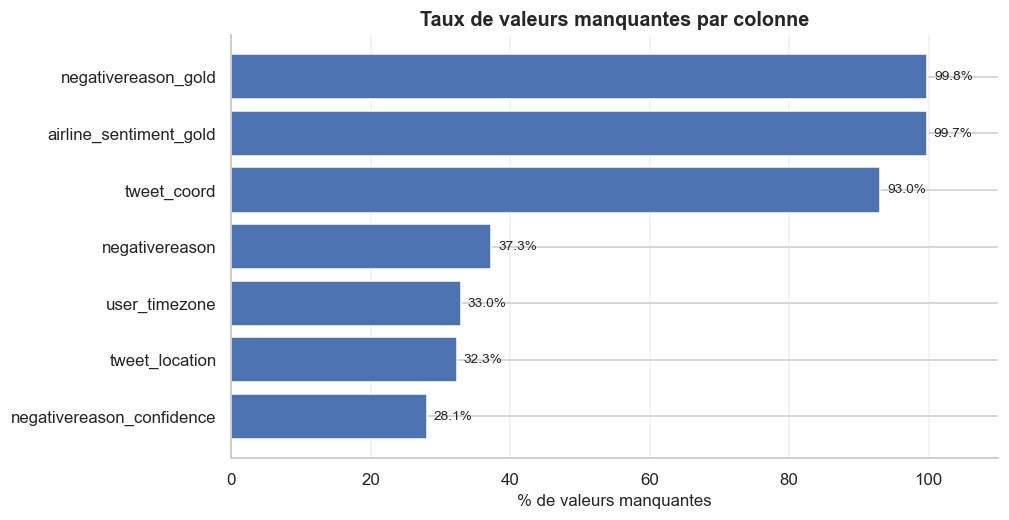

In [4]:
missing = df.isna().mean().mul(100)
missing = missing[missing > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(missing.index, missing.values, color="#4c72b0")
ax.invert_yaxis()
for bar, value in zip(bars, missing.values):
    ax.text(value + 1, bar.get_y() + bar.get_height() / 2, f"{value:.1f}%",
            va="center", fontsize=9)
ax.set_xlim(0, 110)
ax.set_xlabel("% de valeurs manquantes")
ax.set_title("Taux de valeurs manquantes par colonne")
ax.grid(axis="x", alpha=0.3)

print("Colonnes sans aucune valeur manquante :",
      ", ".join(df.columns[df.isna().sum() == 0]))
print(f"Tweets négatifs : {(df.airline_sentiment == 'negative').sum()} "
      f"-> {df.negativereason.notna().sum()} motifs renseignés")

> **Interprétation**
>
> - **Aucune donnée manquante sur `text`, `airline_sentiment` ni `airline`** : les trois colonnes indispensables sont complètes, le problème est donc supervisé et directement exploitable.
> - **`negativereason` manque à 37,3 %**, soit exactement les 5 445 tweets non négatifs : l'absence est **structurelle** (seuls les tweets négatifs ont un motif). Il ne faut surtout pas l'imputer ni l'utiliser comme variable d'entrée, ce serait une fuite de la cible.
> - `airline_sentiment_gold` (99,7 %) et `negativereason_gold` (99,8 %) sont des colonnes quasi vides héritées de l'annotation : à supprimer.
> - `tweet_coord` manque à 93 % : inexploitable. `tweet_location` et `user_timezone` manquent à ~33 % : couverture partielle, et surtout **biais déclaratif** (seuls les utilisateurs ayant rempli leur profil sont géolocalisés).
> - `airline_sentiment_confidence` a une moyenne de 0,90 mais 236 tweets descendent sous 0,50 : c'est une mesure directe du **bruit d'étiquetage**, qui plafonnera les scores.

## 4.2 Distribution de la cible

Le déséquilibre des classes conditionne le choix des métriques et des modèles.

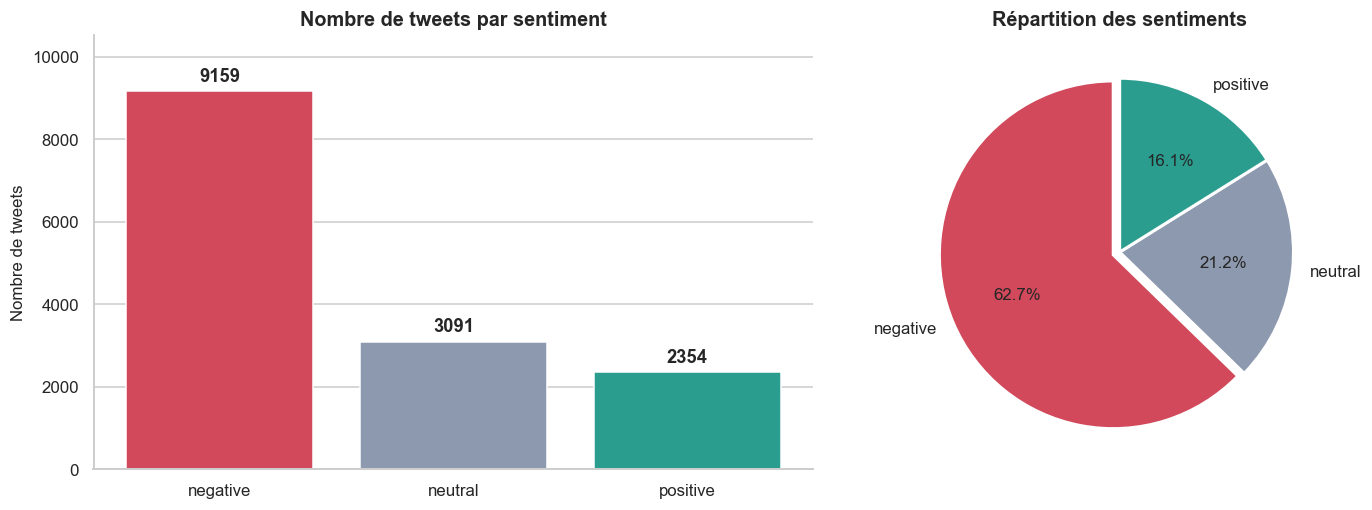

,effectif,part (%),rappel d'une classe majoritaire
airline_sentiment,,,
negative,9159,62.7,62.7
neutral,3091,21.2,62.7
positive,2354,16.1,62.7


Ratio de déséquilibre (négatif / positif) : 3.9 : 1


In [5]:
counts = df["airline_sentiment"].value_counts().reindex(ORDER)
shares = (counts / counts.sum() * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.35, 1]})

bars = axes[0].bar(counts.index, counts.values, color=[PALETTE[c] for c in counts.index])
axes[0].bar_label(bars, fmt="%d", padding=4, fontweight="bold")
axes[0].set_title("Nombre de tweets par sentiment")
axes[0].set_ylabel("Nombre de tweets")
axes[0].set_ylim(0, counts.max() * 1.15)

axes[1].pie(counts.values, labels=counts.index, colors=[PALETTE[c] for c in counts.index],
            autopct="%1.1f%%", startangle=90, explode=(0.04, 0, 0),
            wedgeprops={"edgecolor": "white", "linewidth": 2}, textprops={"fontsize": 11})
axes[1].set_title("Répartition des sentiments")

plt.tight_layout()
plt.show()

summary = pd.DataFrame({"effectif": counts, "part (%)": shares,
                        "rappel d'une classe majoritaire": shares.iloc[0]})
display(summary)
print(f"Ratio de déséquilibre (négatif / positif) : {counts['negative'] / counts['positive']:.1f} : 1")

> **Interprétation**
>
> - **9 159 tweets négatifs (62,7 %)**, 3 091 neutres (21,2 %), 2 354 positifs (16,1 %) : le corpus est fortement déséquilibré (3,9 tweets négatifs pour 1 positif).
> - Conséquence directe : un modèle trivial qui répond toujours « negative » obtient **62,7 % d'accuracy**. L'accuracy seule est donc trompeuse ; on privilégiera le **F1 macro** et le **rappel par classe**, qui pénalisent l'abandon des classes minoritaires.
> - Le fort taux de négativité n'est pas un artefact : le corpus a été constitué en interrogeant les compagnies sur leurs mentions, et les clients mécontents s'expriment davantage. Cette asymétrie est réaliste pour une veille e-réputation.

## 4.3 Sentiment par compagnie

Le sentiment varie-t-il d'une compagnie à l'autre ? Cette vue sert au diagnostic métier, pas à la prédiction (la compagnie n'est pas connue pour un tweet « brut »).

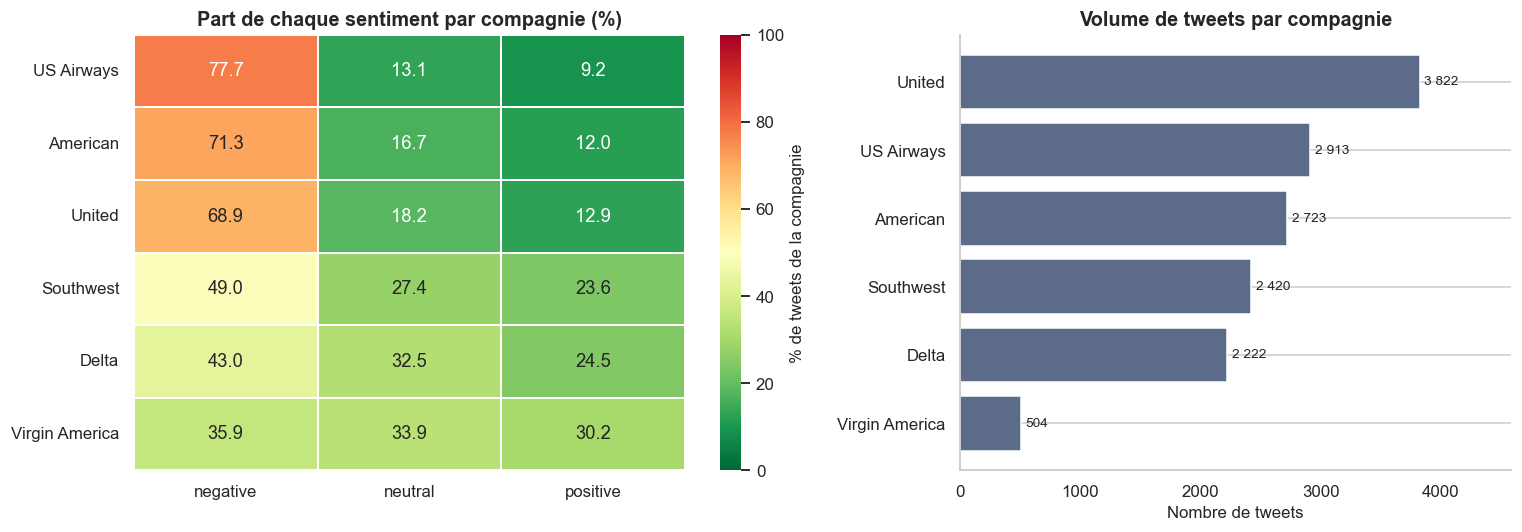

airline_sentiment,negative,neutral,positive
airline,,,
US Airways,77.7,13.1,9.2
American,71.3,16.7,12.0
United,68.9,18.2,12.9
Southwest,49.0,27.4,23.6
Delta,43.0,32.5,24.5
Virgin America,35.9,33.9,30.2


Part des tweets négatifs dans le corpus : 62.7%


In [6]:
ct = pd.crosstab(df["airline"], df["airline_sentiment"])[ORDER]
ct_pct = ct.div(ct.sum(axis=1), axis=0).mul(100)
ct_pct = ct_pct.loc[ct_pct["negative"].sort_values(ascending=False).index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.25, 1]})

sns.heatmap(ct_pct, annot=True, fmt=".1f", cmap="RdYlGn_r", vmin=0, vmax=100,
            linewidths=1, linecolor="white", cbar_kws={"label": "% de tweets de la compagnie"},
            ax=axes[0])
axes[0].set_title("Part de chaque sentiment par compagnie (%)")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

volumes = df["airline"].value_counts()
axes[1].barh(volumes.index[::-1], volumes.values[::-1], color="#5c6b8a")
for i, value in enumerate(volumes.values[::-1]):
    axes[1].text(value + 40, i, f"{value:,}".replace(",", " "), va="center", fontsize=9)
axes[1].set_xlim(0, volumes.max() * 1.2)
axes[1].set_title("Volume de tweets par compagnie")
axes[1].set_xlabel("Nombre de tweets")

plt.tight_layout()
plt.show()

display(ct_pct.round(1))
print("Part des tweets négatifs dans le corpus :", f"{(df.airline_sentiment == 'negative').mean():.1%}")

> **Interprétation**
>
> - Les écarts sont **massifs** : US Airways affiche 77,7 % de tweets négatifs contre 9,2 % de positifs, American 71,3 %, United 68,9 %, tandis que Virgin America descend à 35,9 % de négatifs (30,2 % de positifs) et Delta à 43,0 %. L'écart va presque du simple au double.
> - Ce classement se lit comme un **indicateur de satisfaction** : il reflète des incidents opérationnels réels (annulations, retards) et des différences de culture de service, pas seulement la propension des clients à se plaindre.
> - Le volume est lui aussi très inégal (United 3 822 tweets, Virgin America 504) : la compagnie est donc **corrélée à la cible**. L'utiliser comme variable d'entrée apprendrait au modèle des a priori de marque, non du langage ; on ne garde que le texte.

## 4.4 Raisons de la négativité

Le dataset annote le motif des plaintes : c'est une information métier précieuse pour prioriser les actions.

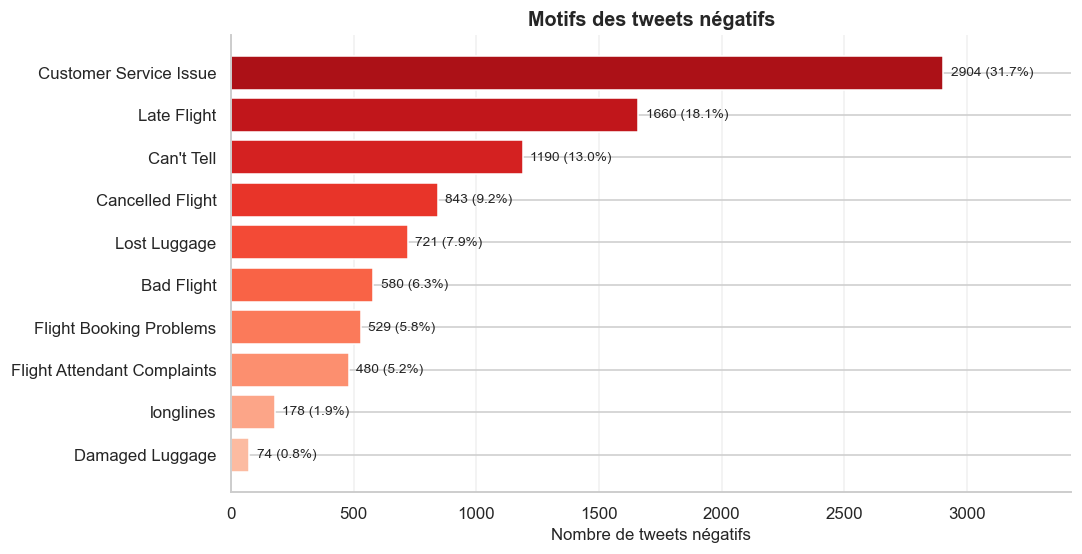

,nombre,part des tweets négatifs
negativereason,,
Customer Service Issue,2904,31.7
Late Flight,1660,18.1
Can't Tell,1190,13.0
Cancelled Flight,843,9.2
Lost Luggage,721,7.9
Bad Flight,580,6.3
Flight Booking Problems,529,5.8
Flight Attendant Complaints,480,5.2
longlines,178,1.9


Tweets négatifs sans motif exploitable ('Can't Tell') : 1190 (13.0%)


In [7]:
neg = df[df["airline_sentiment"] == "negative"]
reasons = neg["negativereason"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5.2))
colors = plt.cm.Reds(np.linspace(0.85, 0.25, len(reasons)))
bars = ax.barh(reasons.index[::-1], reasons.values[::-1], color=colors[::-1])
for bar, value in zip(bars, reasons.values[::-1]):
    ax.text(value + 30, bar.get_y() + bar.get_height() / 2,
            f"{value} ({value / len(neg):.1%})", va="center", fontsize=9)
ax.set_xlim(0, reasons.max() * 1.18)
ax.set_xlabel("Nombre de tweets négatifs")
ax.set_title("Motifs des tweets négatifs")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"nombre": reasons, "part des tweets négatifs": (reasons / len(neg) * 100).round(1)}))
cant_tell = int(reasons.get("Can't Tell", 0))
print(f"Tweets négatifs sans motif exploitable ('Can't Tell') : {cant_tell} ({cant_tell / len(neg):.1%})")

> **Interprétation**
>
> - **Service client (2 904 tweets, 31,7 %)** et **vol en retard (1 660, 18,1 %)** concentrent la moitié des plaintes : ce sont les deux leviers d'amélioration prioritaires.
> - Viennent ensuite les annulations (843, 9,2 %), les bagages perdus (721, 7,9 %) et les mauvais vols (580, 6,3 %) : des événements ponctuels mais à fort impact émotionnel.
> - **1 190 tweets (13,0 %) sont classés « Can't Tell »** : plainte sans cause identifiable par l'annotateur. C'est une zone d'incertitude qui explique une partie des erreurs du modèle — et un rappel que la frontière `negative`/`neutral` est parfois subjective.
> - Le motif est une conséquence du sentiment, pas une cause observable *a priori* : il ne doit jamais entrer dans les features (fuite).

## 4.5 Dynamique temporelle

Le corpus couvre 9 jours. On regarde le volume quotidien et la répartition horaire.

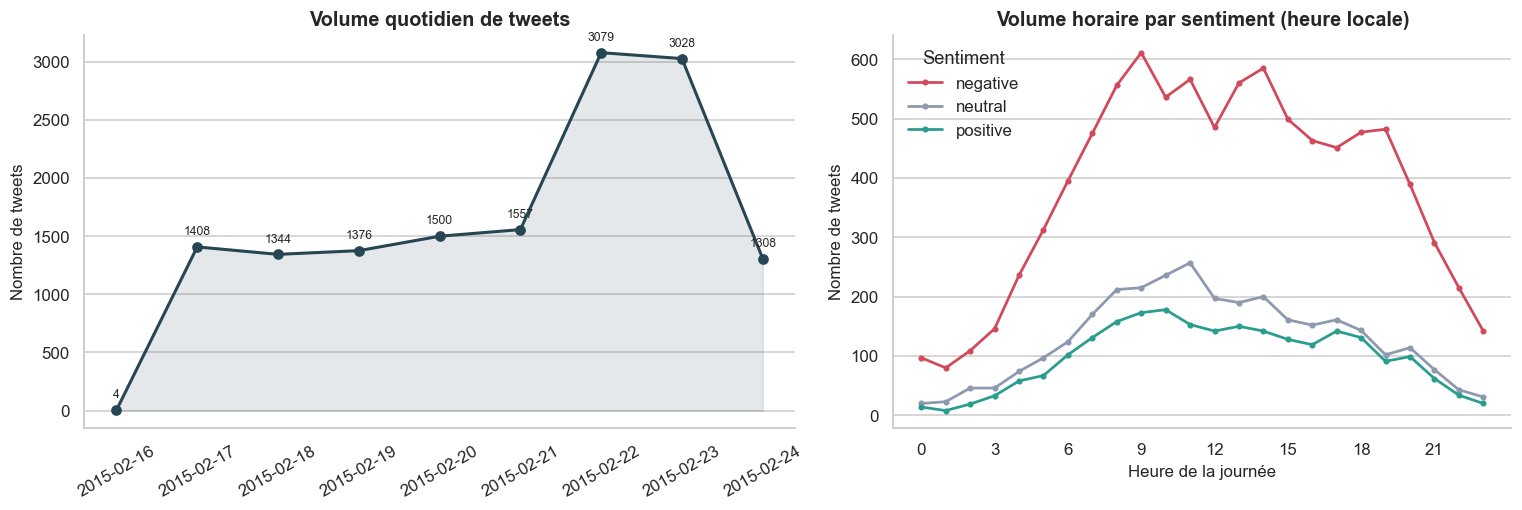

tweet_local
2015-02-16 00:00:00-08:00       4
2015-02-17 00:00:00-08:00    1408
2015-02-18 00:00:00-08:00    1344
2015-02-19 00:00:00-08:00    1376
2015-02-20 00:00:00-08:00    1500
2015-02-21 00:00:00-08:00    1557
2015-02-22 00:00:00-08:00    3079
2015-02-23 00:00:00-08:00    3028
2015-02-24 00:00:00-08:00    1308
Freq: D, Name: tweets, dtype: int64

Pic d'activité : 22/02/2015 avec 3079 tweets (2.2x la médiane)


In [8]:
daily = df.set_index("tweet_local").resample("D").size()
hourly = (df.groupby([df["tweet_local"].dt.hour, "airline_sentiment"])
            .size().unstack()[ORDER])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})

axes[0].plot(daily.index, daily.values, marker="o", color="#264653", linewidth=2)
axes[0].fill_between(daily.index, daily.values, color="#264653", alpha=0.12)
for x, y in zip(daily.index, daily.values):
    axes[0].annotate(f"{y}", (x, y), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=8)
axes[0].set_title("Volume quotidien de tweets")
axes[0].set_ylabel("Nombre de tweets")
axes[0].tick_params(axis="x", rotation=30)

for sentiment in ORDER:
    axes[1].plot(hourly.index, hourly[sentiment], marker="o", markersize=3,
                 label=sentiment, color=PALETTE[sentiment], linewidth=1.8)
axes[1].set_title("Volume horaire par sentiment (heure locale)")
axes[1].set_xlabel("Heure de la journée")
axes[1].set_ylabel("Nombre de tweets")
axes[1].set_xticks(range(0, 24, 3))
axes[1].legend(title="Sentiment", frameon=False)

plt.tight_layout()
plt.show()

display(daily.rename("tweets"))
print(f"Pic d'activité : {daily.idxmax():%d/%m/%Y} avec {daily.max()} tweets "
      f"({daily.max() / daily.median():.1f}x la médiane)")

> **Interprétation**
>
> - Le 16 février ne contient que 4 tweets (début de collecte) ; le rythme de croisière est de ~1 350-1 560 tweets/jour.
> - **Les 22 et 23 février font plus du double (3 079 et 3 028 tweets)** : cet afflux brutal traduit un événement opérationnel majeur (tempêtes et annulations en série aux États-Unis à cette date), qui a mécaniquement gonflé le volume de plaintes. Un tel pic est un signal de veille utile en production.
> - La distribution horaire suit les heures d'activité américaines (pic entre 8 h et 18 h, heure du Pacifique) ; les tweets négatifs dominent à chaque heure, sans inversion : **le déséquilibre n'est pas un artefact horaire**.
> - Conséquence méthodologique : la fenêtre de 9 jours est trop courte pour conclure à une saisonnalité. On n'utilisera ni la date ni l'heure comme features (risque d'apprendre l'incident plutôt que le langage).

## 4.6 Longueur des tweets et viralité

Deux variables faciles à obtenir, dont on vérifie le pouvoir discriminant avant de les intégrer.

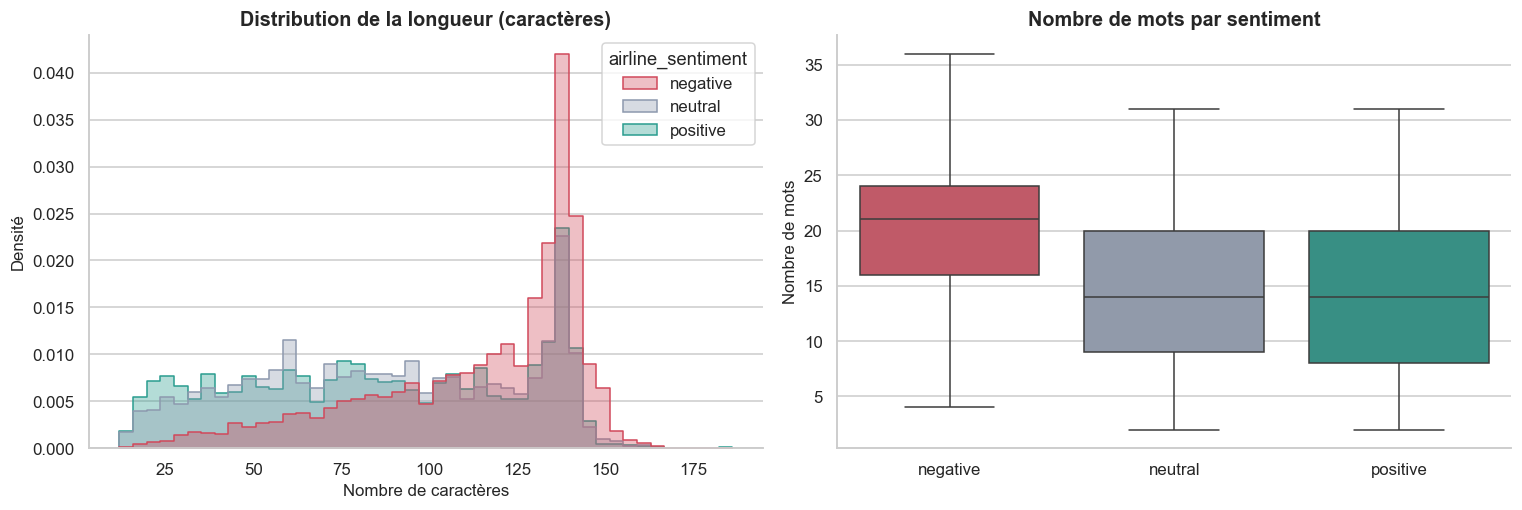

n_chars              n_words            
                     mean median   std    mean median  std
airline_sentiment                                         
negative            113.9  126.0  30.7    19.7   21.0  5.9
neutral              87.4   87.0  37.7    14.4   14.0  7.0
positive             86.1   86.0  39.4    14.0   14.0  7.0

Tweets jamais retweetés : 94.8% | maximum de retweets : 44


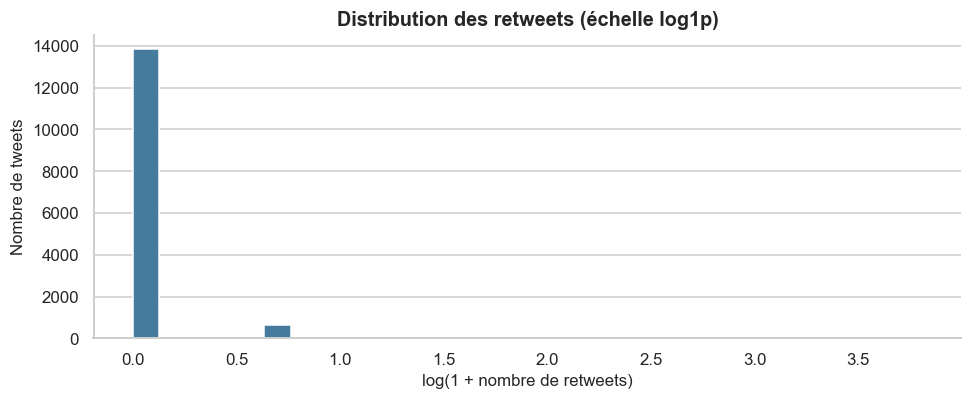

In [9]:
df["n_chars"] = df["text"].str.len()
df["n_words"] = df["text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.histplot(data=df, x="n_chars", hue="airline_sentiment", hue_order=ORDER,
             palette=PALETTE, bins=45, element="step", fill=True, alpha=0.35,
             common_norm=False, stat="density", ax=axes[0])
axes[0].set_title("Distribution de la longueur (caractères)")
axes[0].set_xlabel("Nombre de caractères")
axes[0].set_ylabel("Densité")

sns.boxplot(data=df, x="airline_sentiment", y="n_words", order=ORDER, hue="airline_sentiment",
            palette=PALETTE, legend=False, showfliers=False, ax=axes[1])
axes[1].set_title("Nombre de mots par sentiment")
axes[1].set_xlabel("")
axes[1].set_ylabel("Nombre de mots")

plt.tight_layout()
plt.show()

length_stats = (df.groupby("airline_sentiment")[["n_chars", "n_words"]]
                  .agg(["mean", "median", "std"]).round(1).reindex(ORDER))
display(length_stats)

retweeted = (df["retweet_count"] > 0).mean()
print(f"Tweets jamais retweetés : {1 - retweeted:.1%} | maximum de retweets : {df.retweet_count.max()}")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(np.log1p(df["retweet_count"]), bins=30, color="#457b9d")
ax.set_title("Distribution des retweets (échelle log1p)")
ax.set_xlabel("log(1 + nombre de retweets)")
ax.set_ylabel("Nombre de tweets")
plt.tight_layout()
plt.show()

> **Interprétation**
>
> - Les tweets négatifs sont **nettement plus longs** : 113,9 caractères et 19,7 mots en moyenne, contre 87,4 / 14,4 pour les neutres et 86,1 / 14,0 pour les positifs — soit environ **40 % de mots en plus**. Une plainte argumente (numéro de vol, durée d'attente, demande de remboursement), un remerciement est bref.
> - Les distributions se recouvrent toutefois largement : la longueur **seule** ne suffit pas à classer, mais c'est une variable d'appoint pertinente — d'où son intégration au feature engineering (§5.3).
> - **94,8 % des tweets ne sont jamais retweetés** (maximum 44) : la viralité est quasi inexistante dans ce corpus. `retweet_count` est donc une variable quasi constante, **écartée** du modèle.

## 4.7 Origine géographique

Un rapide contrôle de la couverture géographique, pour documenter les biais de collecte.

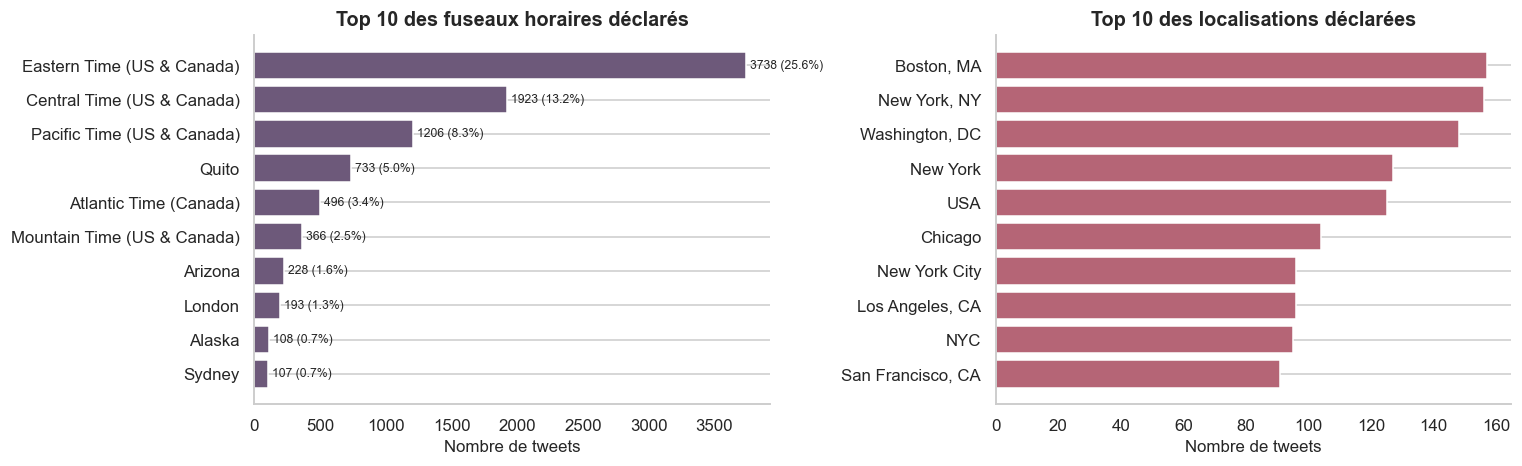

Fuseau horaire renseigné : 67.0% | localisation renseignée : 67.7%
Coordonnées GPS renseignées : 7.0%


In [10]:
tz = df["user_timezone"].value_counts().head(10)
loc = df["tweet_location"].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))

axes[0].barh(tz.index[::-1], tz.values[::-1], color="#6d597a")
axes[0].set_title("Top 10 des fuseaux horaires déclarés")
axes[0].set_xlabel("Nombre de tweets")
for i, value in enumerate(tz.values[::-1]):
    axes[0].text(value + 30, i, f"{value} ({value / len(df):.1%})", va="center", fontsize=8)

axes[1].barh(loc.index[::-1], loc.values[::-1], color="#b56576")
axes[1].set_title("Top 10 des localisations déclarées")
axes[1].set_xlabel("Nombre de tweets")

plt.tight_layout()
plt.show()

print(f"Fuseau horaire renseigné : {df.user_timezone.notna().mean():.1%} | "
      f"localisation renseignée : {df.tweet_location.notna().mean():.1%}")
print(f"Coordonnées GPS renseignées : {df.tweet_coord.notna().mean():.1%}")

> **Interprétation**
>
> - La couverture est très majoritairement américaine (Eastern 25,6 %, Central 13,2 %, Pacific 8,3 %), cohérente avec des compagnies américaines. La présence de **Quito (~730 tweets, 5,0 %)** est surprenante et illustre le bruit des profils déclaratifs.
> - Les villes les plus représentées sont Boston, New York et Washington, mais avec seulement ~150 tweets chacune : la localisation est trop fragmentée pour être une feature fiable.
> - **Un tiers des tweets n'a ni fuseau ni localisation**, et les coordonnées GPS manquent à 93 % : toute analyse géographique serait biaisée. Ces colonnes sont donc réservées au descriptif, pas au modèle.

## 4.8 Vocabulaire par sentiment

Avant le nettoyage complet, on compare les mots les plus fréquents de chaque classe (mots vides retirés, mentions supprimées) et on visualise des nuages de mots.

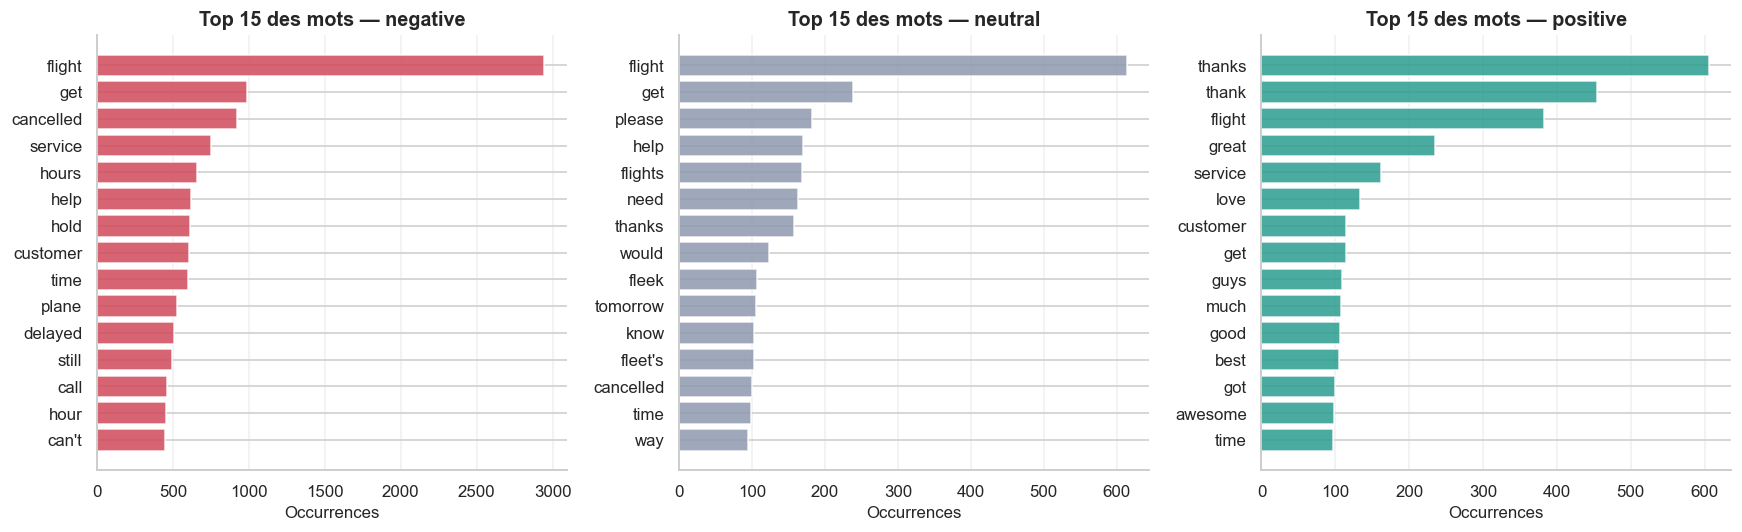

 negative : flight (2946), get (990), cancelled (921), service (748), hours (656), help (618), hold (611), customer (609), time (597), plane (525)
  neutral : flight (614), get (238), please (182), help (170), flights (169), need (163), thanks (157), would (123), fleek (107), tomorrow (106)
 positive : thanks (606), thank (454), flight (382), great (235), service (162), love (134), customer (114), get (114), guys (109), much (108)


In [11]:
EDA_STOPWORDS = set(stopwords.words("english")) | {"amp", "http", "https", "www", "im", "ive"}


def eda_words(text):
    '''Tokenisation légère réservée à l'exploration visuelle.'''
    text = re.sub(r"http\S+|www\.\S+", " ", str(text).lower())
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    return [w.strip("'") for w in text.split()
            if w not in EDA_STOPWORDS and len(w.strip("'")) > 2]


top_words = {sentiment: Counter(w for t in df.loc[df.airline_sentiment == sentiment, "text"]
                                for w in eda_words(t)).most_common(15)
             for sentiment in ORDER}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, sentiment in zip(axes, ORDER):
    words, values = zip(*top_words[sentiment])
    ax.barh(list(words)[::-1], list(values)[::-1], color=PALETTE[sentiment], alpha=0.85)
    ax.set_title(f"Top 15 des mots — {sentiment}")
    ax.set_xlabel("Occurrences")
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

for sentiment in ORDER:
    print(f"{sentiment:>9} : " + ", ".join(f"{w} ({c})" for w, c in top_words[sentiment][:10]))

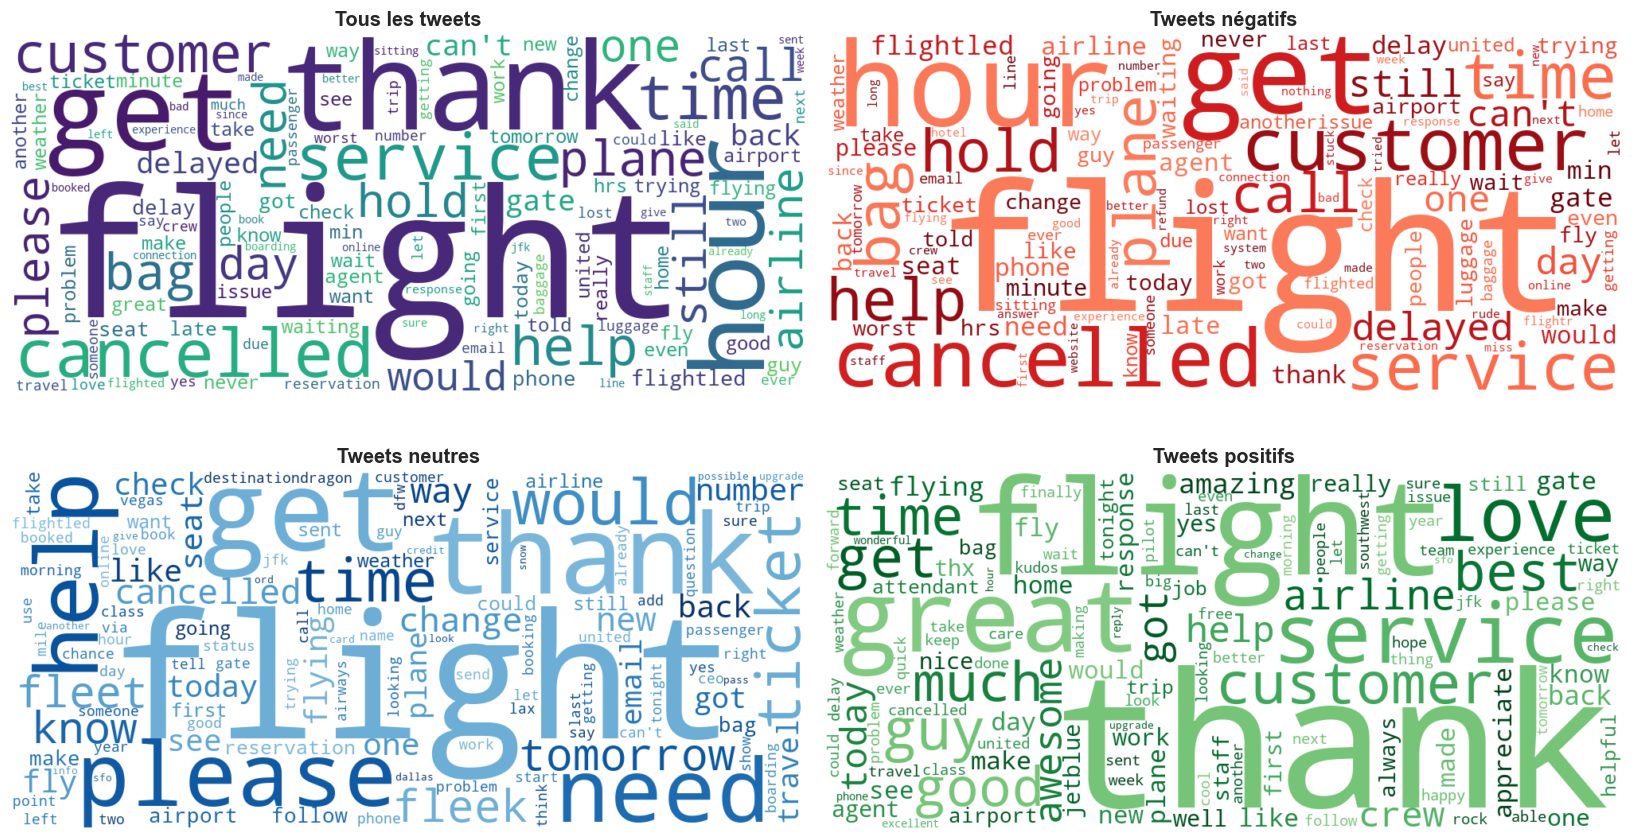

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
cloud_specs = [
    ("Tous les tweets", df["text"], ListedColormap(plt.cm.viridis(np.linspace(0.05, 0.75, 256)))),
    ("Tweets négatifs", df.loc[df.airline_sentiment == "negative", "text"],
     ListedColormap(plt.cm.Reds(np.linspace(0.40, 1.0, 256)))),
    ("Tweets neutres", df.loc[df.airline_sentiment == "neutral", "text"],
     ListedColormap(plt.cm.Blues(np.linspace(0.45, 1.0, 256)))),
    ("Tweets positifs", df.loc[df.airline_sentiment == "positive", "text"],
     ListedColormap(plt.cm.Greens(np.linspace(0.45, 1.0, 256)))),
]

for ax, (title, texts, cmap) in zip(axes.ravel(), cloud_specs):
    corpus = " ".join(" ".join(eda_words(t)) for t in texts)
    cloud = WordCloud(width=1000, height=450, background_color="white", colormap=cmap,
                      stopwords=EDA_STOPWORDS, max_words=120, collocations=False,
                      random_state=RANDOM_STATE).generate(corpus)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

> **Interprétation**
>
> - **Négatif** : *cancelled*, *service*, *hours*, *hold*, *delayed*, *customer*, *call*, *lost*, *bag* — le lexique de l'incident et de l'attente. Les plaintes sont **factuelles et circonstanciées**.
> - **Positif** : *thanks*, *thank*, *great*, *love*, *awesome*, *best*, *crew*, *friendly* — remerciements et superlatifs. Le vocabulaire positif est **beaucoup plus stéréotypé**, ce qui aide le modèle malgré le faible effectif de la classe.
> - **Neutre** : *please*, *help*, *need*, *tomorrow*, *would*, *know* — questions, demandes d'information, tweets de service client. C'est la classe la plus **hétérogène**, donc la plus difficile à cerner.
> - Les nuages confirment que les classes sont lexicalement séparables, mais les mots partagés (*flight*, *get*, *time*, *plane*) sont partout : un simple sac de mots devra s'appuyer sur des combinaisons et des négations, d'où l'intérêt des bigrammes et des variables de contexte.

# 5. Feature engineering

## 5.1 Stratégie

Un modèle linéaire sur un sac de mots brut plafonne vite sur ce corpus. On construit **trois familles complémentaires** de représentations, assemblées dans une matrice creuse unique :

| Famille | Exemples | Ce qu'elle apporte |
|---|---|---|
| **1. Texte vectorisé** | TF-IDF mots (1-2 grammes) + TF-IDF caractères (3-5 grammes) | sémantique lexicale, expressions (*"on hold"*, *"never again"*), robustesse aux fautes et abréviations via les caractères |
| **2. Variables linguistiques** | longueur, diversité lexicale, mentions, hashtags, majuscules, ponctuation, négations | signaux de style et d'intensité que le TF-IDF ne capte pas |
| **3. Variables lexicales de sentiment** | VADER (négatif / neutre / positif / composé) | polarité *a priori* du texte, indépendante des labels |

**Règles anti-fuite appliquées systématiquement :**

- les vectoriseurs et le *scaling* sont **ajustés sur le train uniquement**, jamais sur le test ;
- `negativereason` (motif de plainte), `airline` (compagnie), la date et le score de confiance sont **exclus** : ils ne sont pas disponibles pour un tweet inconnu, ou encodent la réponse ;
- les doublons stricts ont été retirés (§3).

## 5.2 Nettoyage du texte

Le nettoyage doit **préserver les négations** (*not*, *never*, *no*…) et la ponctuation porteuse de sens. On normalise les contractions, on supprime les URLs et les mentions (leur nombre devient une feature), on réduit les répétitions (*sooooo* → *soo*) et on lemmatise pour regrouper les formes fléchies (*delayed*, *delays* → *delay*). Un cache évite de lemmatiser deux fois le même mot.

In [13]:
CONTRACTIONS = {
    "won't": "will not", "can't": "can not", "shan't": "shall not", "cannot": "can not",
    "wanna": "want to", "gonna": "going to", "gotta": "got to", "kinda": "kind of",
    "ur": "your", "u": "you", "r": "are", "pls": "please", "plz": "please",
    "thx": "thanks", "thanx": "thanks", "ppl": "people", "bc": "because", "b4": "before",
}
_SUFFIX_EXPANSIONS = {"s": "is", "re": "are", "ll": "will", "ve": "have", "d": "would", "m": "am"}
NEGATIONS = {"not", "no", "never", "none", "nothing", "nobody", "neither", "nor",
             "cannot", "without", "hardly", "barely"}
# On retire les stopwords MAIS on conserve les négations et les intensificateurs,
# qui portent le sentiment ("not good", "very delayed", "too long").
ML_STOPWORDS = set(stopwords.words("english")) - NEGATIONS - {
    "very", "too", "so", "just", "still", "but", "more", "most", "only", "again"
}
LEMMATIZER = WordNetLemmatizer()


@lru_cache(maxsize=100_000)
def _lemma(token):
    return LEMMATIZER.lemmatize(LEMMATIZER.lemmatize(token, "n"), "v")


def _expand_tokens(text):
    '''Développe les contractions et abréviations **mot par mot** (jamais en sous-chaîne).'''
    expanded = []
    for token in re.findall(r"[a-z]+(?:'[a-z]+)?", text):
        token = token.strip("'")
        if not token:
            continue
        if token in CONTRACTIONS:
            expanded.extend(CONTRACTIONS[token].split())
        elif token.endswith("n't") and len(token) > 3:      # don't -> do not
            expanded.extend([token[:-3], "not"])
        elif "'" in token:                                   # you're -> you are
            stem, _, suffix = token.rpartition("'")
            if stem and suffix in _SUFFIX_EXPANSIONS:
                expanded.extend([stem, _SUFFIX_EXPANSIONS[suffix]])
            else:
                expanded.append(token.replace("'", ""))
        else:
            expanded.append(token)
    return expanded


def clean_text(text, keep_negations=True):
    '''Normalise un tweet et renvoie une chaîne de lemmes séparés par des espaces.'''
    if not isinstance(text, str) or not text.strip():
        return ""

    text = html.unescape(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " url ", text)      # URLs -> jeton unique
    text = re.sub(r"@\w+", " ", text)                       # mentions (comptées à part)
    text = re.sub(r"#(\w+)", r" \1 ", text)                 # hashtags -> mot nu
    text = re.sub(r"(\w)\1{2,}", r"\1\1", text)             # "sooooo" -> "soo"

    tokens = []
    for token in _expand_tokens(text):
        if token in ML_STOPWORDS and not (keep_negations and token in NEGATIONS):
            continue
        if len(token) < 2 and token not in NEGATIONS:
            continue
        tokens.append(_lemma(token))
    return " ".join(tokens)


demo = pd.DataFrame({
    "tweet original": [
        "@united our flight was delayed 3 hours, NOT happy at all!!!",
        "Thanks @SouthwestAir, the crew was sooooo friendly :)",
        "Don't fly @AmericanAir, they never help when bags are lost.",
        "Is there a shuttle to the terminal?",
    ]
})
demo["après nettoyage"] = demo["tweet original"].map(clean_text)
demo

,tweet original,après nettoyage
0,"@united our flight was delayed 3 hours, NOT happy at all!!!",flight delay hour not happy
1,"Thanks @SouthwestAir, the crew was sooooo friendly :)",thank crew soo friendly
2,"Don't fly @AmericanAir, they never help when bags are lost.",not fly never help bag lose
3,Is there a shuttle to the terminal?,shuttle terminal


> **Interprétation du nettoyage**
>
> - `NOT` devient `not` et **survit** au filtre de stopwords : `"was delayed 3 hours, NOT happy"` restitue la négation au lieu de produire un faux positif.
> - `sooooo` → `soo`, `:)` disparaît, `@united` est retiré (le nombre de mentions devient une variable) : le bruit de surface est éliminé sans perdre le contenu.
> - `delayed` → `delay`, `bags` → `bag` : les variantes morphologiques sont fusionnées, ce qui réduit la dimension et améliore la généralisation.
> - Les nombres (`3 hours`) quittent le texte mais restent disponibles via `n_digits` : l'information est **déplacée** vers une variable dédiée plutôt que perdue.
> - La ponctuation expressive (`!!!`) disparaît du texte mais sera récupérée comme **comptage** dans les variables engineered — même logique de complémentarité.
> - Le développement des contractions se fait **mot par mot** (`_expand_tokens`) : une substitution en sous-chaîne transformerait *commercials* en *commearecials*. Ce détail de mise en œuvre est décisif pour la qualité du vocabulaire.

## 5.3 Variables engineered

Pour chaque tweet, on calcule 22 variables réparties en quatre blocs :

- **taille et richesse** : caractères, mots, longueur moyenne des mots, mots uniques, diversité lexicale ;
- **style Twitter** : mentions, hashtags, URLs, majuscules, ratio de majuscules, chiffres, ponctuation, points de suspension ;
- **expressivité / grammaire** : exclamations, questions, négations, présence de négation, part de stopwords ;
- **polarité lexicale (VADER)** : scores négatif, neutre, positif et composé.

In [14]:
META_FEATURES = [
    "n_chars", "n_words", "avg_word_len", "n_unique_words", "lexical_diversity",
    "n_mentions", "n_hashtags", "n_urls", "n_exclam", "n_question", "n_ellipsis",
    "n_upper_words", "caps_ratio", "n_digits", "n_punct",
    "n_negations", "has_negation", "stopword_ratio",
    "vader_neg", "vader_neu", "vader_pos", "vader_compound",
]

_NEGATION_PATTERN = re.compile(
    r"\b(?:not|no|never|none|nothing|nobody|neither|nor|cannot|can't|won't|don't|"
    r"doesn't|didn't|isn't|aren't|wasn't|weren't|shouldn't|couldn't|wouldn't|"
    r"hasn't|haven't|hadn't|without|hardly|barely)\b"
)
_VADER = SentimentIntensityAnalyzer()
_ALL_STOPWORDS = set(stopwords.words("english"))


def extract_meta_features(texts):
    '''Calcule les 22 variables linguistiques pour une série de tweets bruts.'''
    s = pd.Series(list(texts) if not isinstance(texts, pd.Series) else texts)
    s = s.astype(str).reset_index(drop=True).fillna("")
    low = s.str.lower()
    words = low.str.split()

    feats = pd.DataFrame(index=s.index)
    feats["n_chars"] = s.str.len().astype(float)
    feats["n_words"] = words.str.len().astype(float)
    feats["avg_word_len"] = words.apply(
        lambda ws: float(np.mean([len(w) for w in ws])) if ws else 0.0)
    feats["n_unique_words"] = words.apply(lambda ws: float(len(set(ws))))
    feats["lexical_diversity"] = np.where(feats["n_words"] > 0,
                                          feats["n_unique_words"] / feats["n_words"].replace(0, 1), 0.0)

    feats["n_mentions"] = s.str.count(r"@\w+").astype(float)
    feats["n_hashtags"] = s.str.count(r"#\w+").astype(float)
    feats["n_urls"] = s.str.count(r"http\S+|www\.\S+").astype(float)
    feats["n_exclam"] = s.str.count("!").astype(float)
    feats["n_question"] = s.str.count(r"\?").astype(float)
    feats["n_ellipsis"] = s.str.count(r"\.\.\.|…").astype(float)
    feats["n_upper_words"] = s.apply(
        lambda t: float(sum(1 for w in t.split() if w.isupper() and len(w) > 1)))
    letters = s.str.count(r"[A-Za-z]").replace(0, np.nan)
    feats["caps_ratio"] = (s.str.count(r"[A-Z]") / letters).fillna(0.0)
    feats["n_digits"] = s.str.count(r"\d").astype(float)
    feats["n_punct"] = s.str.count(r"[^\w\s]").astype(float)

    feats["n_negations"] = low.str.count(_NEGATION_PATTERN).astype(float)
    feats["has_negation"] = (feats["n_negations"] > 0).astype(float)
    feats["stopword_ratio"] = words.apply(
        lambda ws: float(np.mean([w in _ALL_STOPWORDS for w in ws])) if ws else 0.0)

    vader = s.apply(lambda t: _VADER.polarity_scores(t))
    feats["vader_neg"] = vader.apply(lambda d: d["neg"]).astype(float)
    feats["vader_neu"] = vader.apply(lambda d: d["neu"]).astype(float)
    feats["vader_pos"] = vader.apply(lambda d: d["pos"]).astype(float)
    feats["vader_compound"] = vader.apply(lambda d: d["compound"]).astype(float)

    return feats[META_FEATURES].fillna(0.0)


data = df.drop(columns=["n_chars", "n_words"], errors="ignore").reset_index(drop=True)
data["target"] = data["airline_sentiment"].astype(str).map({"negative": 0, "neutral": 1, "positive": 2}).astype(int)
data["clean"] = data["text"].map(clean_text)
data = pd.concat([data, extract_meta_features(data["text"])], axis=1)

print(f"Variables engineered : {len(META_FEATURES)} | matrice : {data[META_FEATURES].shape}")
data[["text", "clean"] + META_FEATURES[:6]].head(4)

Variables engineered : 22 | matrice : (14604, 22)


,text,clean,n_chars,n_words,avg_word_len,n_unique_words,lexical_diversity,n_mentions
0,@VirginAmerica What @dhepburn said.,say,35.0,4.0,8.000000,4.0,1.000000,2.0
1,@VirginAmerica plus you've added commercials to the experience... tacky.,plus add commercial experience tacky,72.0,9.0,7.111111,9.0,1.000000,1.0
2,@VirginAmerica I didn't today... Must mean I need to take another trip!,not today must mean need take another trip,71.0,12.0,5.000000,11.0,0.916667,1.0
3,"@VirginAmerica it's really aggressive to blast obnoxious ""entertainment"" in your guests' faces &...",really aggressive blast obnoxious entertainment guest face little recourse,126.0,17.0,6.470588,17.0,1.000000,1.0


**Contrôle de cohérence.** On vérifie la distribution des variables et l'absence de valeurs aberrantes ou de colonnes constantes avant de les utiliser.

In [15]:
overview = data[META_FEATURES].describe().T
overview["manquants"] = data[META_FEATURES].isna().sum().values
overview["constante"] = overview["std"].round(6) == 0
overview.round(3)

,count,mean,std,min,25%,50%,75%,max,manquants,constante
n_chars,14604.0,103.828,36.259,12.000,77.000,114.000,136.000,186.000,0,False
n_words,14604.0,17.656,6.880,2.000,12.000,19.000,23.000,36.000,0,False
avg_word_len,14604.0,5.160,1.140,3.154,4.423,4.909,5.571,18.500,0,False
n_unique_words,14604.0,16.750,6.260,2.000,12.000,18.000,22.000,32.000,0,False
lexical_diversity,14604.0,0.958,0.053,0.429,0.926,1.000,1.000,1.000,0,False
n_mentions,14604.0,1.128,0.404,1.000,1.000,1.000,1.000,6.000,0,False
n_hashtags,14604.0,0.239,0.654,0.000,0.000,0.000,0.000,8.000,0,False
n_urls,14604.0,0.083,0.285,0.000,0.000,0.000,0.000,3.000,0,False
n_exclam,14604.0,0.363,0.920,0.000,0.000,0.000,0.000,27.000,0,False
n_question,14604.0,0.320,0.661,0.000,0.000,0.000,1.000,11.000,0,False


## 5.4 Analyse des variables engineered

Deux questions : ces variables sont-elles **liées** au sentiment, et **redondantes** entre elles ? On mesure la corrélation de Spearman avec la cible ordinale (négatif = 0, neutre = 1, positif = 2), puis l'information mutuelle, qui capte aussi les relations non linéaires.

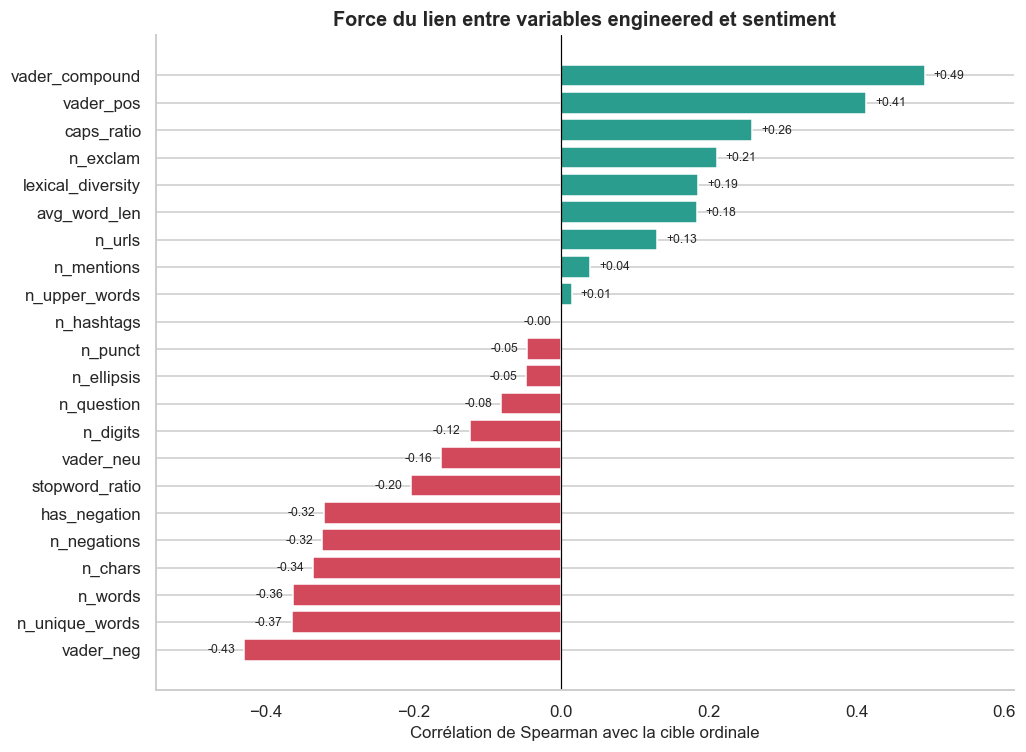

In [16]:
rho = (data[META_FEATURES + ["target"]]
       .corr(method="spearman")["target"]
       .drop("target")
       .sort_values())

fig, ax = plt.subplots(figsize=(9.5, 7))
colors = ["#d1495b" if v < 0 else "#2a9d8f" for v in rho.values]
ax.barh(rho.index, rho.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
for i, value in enumerate(rho.values):
    ax.text(value + (0.012 if value >= 0 else -0.012), i, f"{value:+.2f}",
            va="center", ha="left" if value >= 0 else "right", fontsize=8)
ax.set_xlim(rho.min() - 0.12, rho.max() + 0.12)
ax.set_xlabel("Corrélation de Spearman avec la cible ordinale")
ax.set_title("Force du lien entre variables engineered et sentiment")
plt.tight_layout()
plt.show()

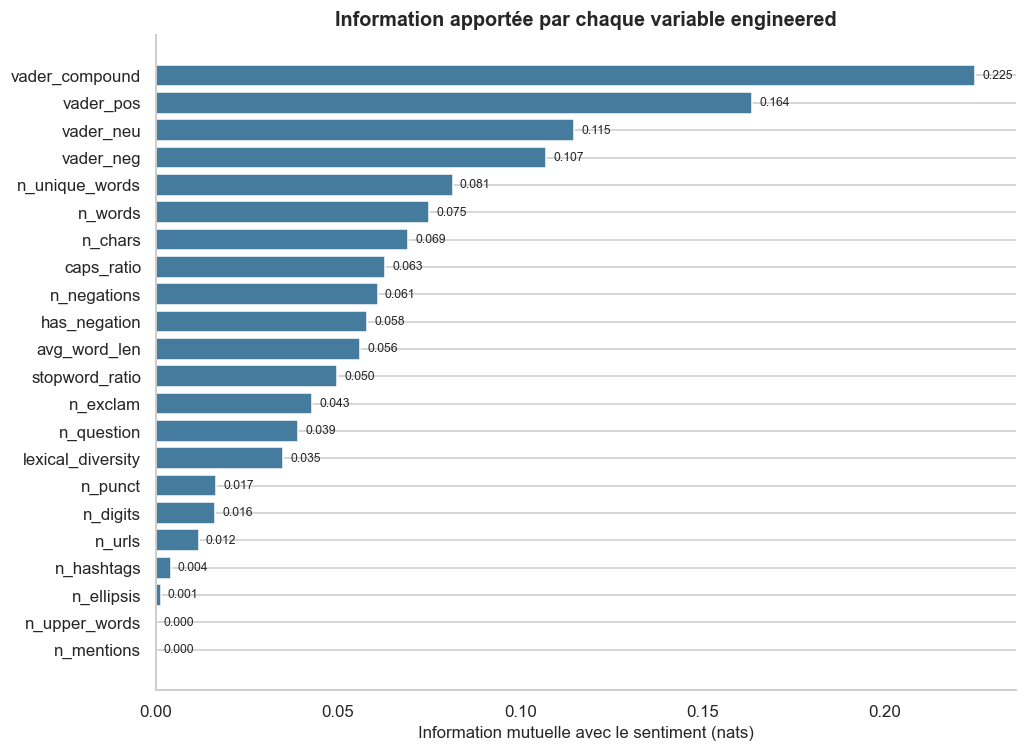

In [17]:
mi = mutual_info_classif(data[META_FEATURES], data["target"], random_state=RANDOM_STATE)
mi = pd.Series(mi, index=META_FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(9.5, 7))
ax.barh(mi.index, mi.values, color="#457b9d")
for i, value in enumerate(mi.values):
    ax.text(value + 0.002, i, f"{value:.3f}", va="center", fontsize=8)
ax.set_xlabel("Information mutuelle avec le sentiment (nats)")
ax.set_title("Information apportée par chaque variable engineered")
plt.tight_layout()
plt.show()

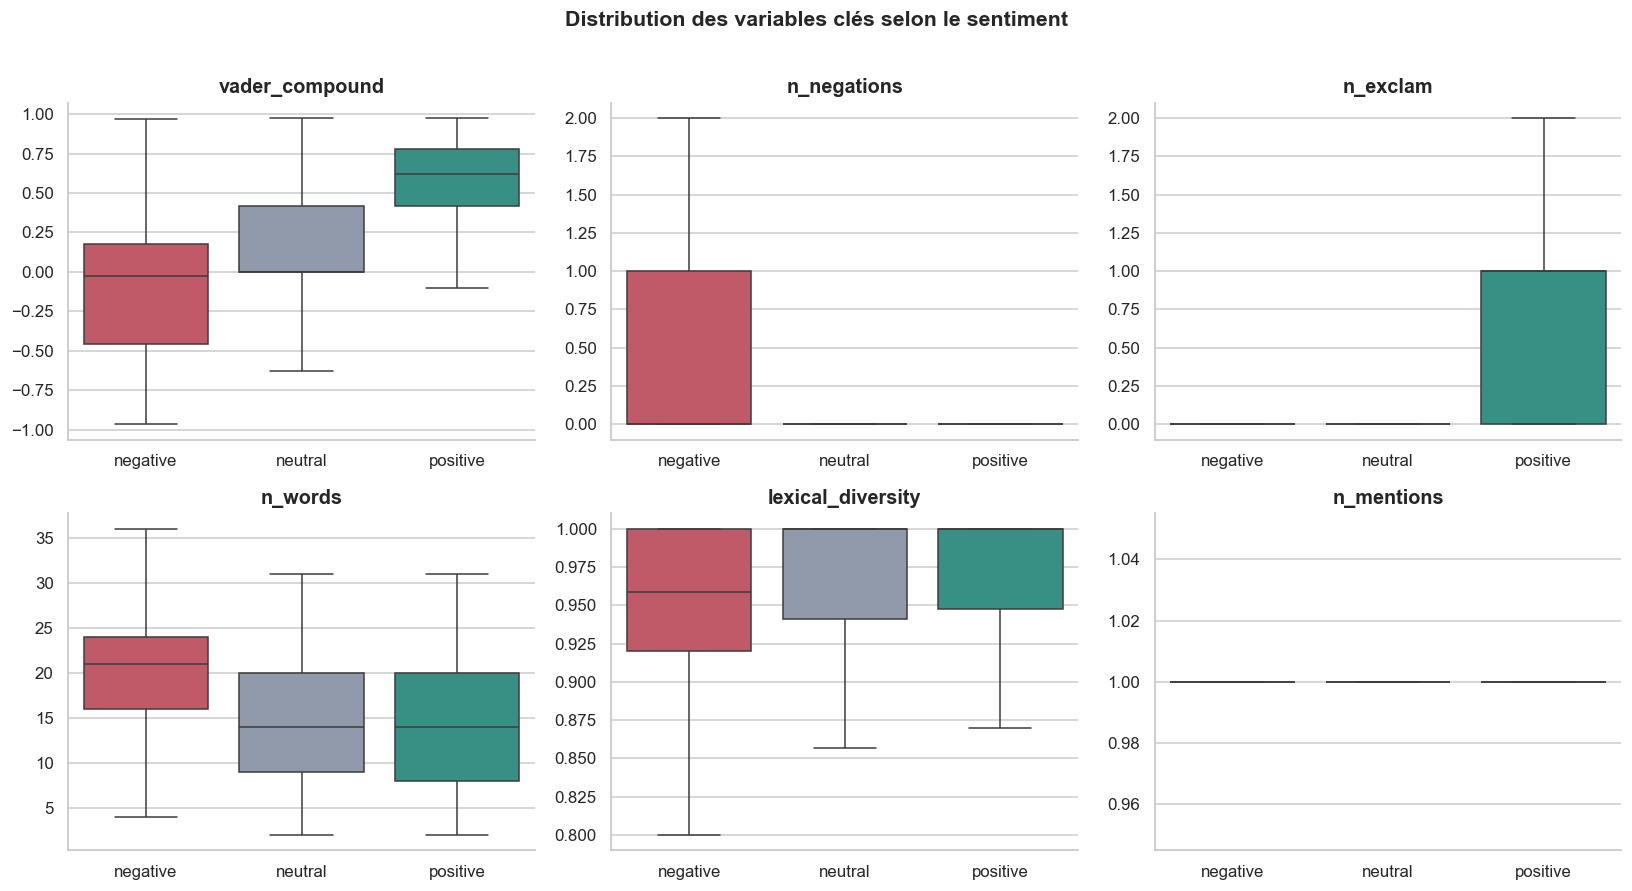

,vader_compound,n_negations,n_exclam,n_words,lexical_diversity,n_mentions
airline_sentiment,,,,,,
negative,-0.106,0.553,0.289,19.683,0.952,1.111
neutral,0.152,0.166,0.217,14.417,0.967,1.168
positive,0.539,0.122,0.843,14.021,0.971,1.138


In [18]:
selected = ["vader_compound", "n_negations", "n_exclam", "n_words", "lexical_diversity", "n_mentions"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feature in zip(axes.ravel(), selected):
    sns.boxplot(data=data, x="airline_sentiment", y=feature, order=ORDER,
                hue="airline_sentiment", palette=PALETTE, legend=False,
                showfliers=False, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Distribution des variables clés selon le sentiment", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

display(data.groupby("airline_sentiment")[selected].mean().round(3).reindex(ORDER))

> **Interprétation**
>
> - **`vader_compound` est de loin la variable la plus informative** : corrélation de Spearman de **+0,49** avec la cible et information mutuelle maximale (**0,225 nat**). Viennent ensuite `vader_neg` (-0,43) et `vader_pos` (+0,41). Le lexique VADER capte l'orientation générale, mais il se trompe sur les plaintes formulées sans mot négatif (*« on hold for 1hr »*) — d'où l'intérêt de le **combiner** au TF-IDF plutôt que de l'utiliser seul.
> - **La longueur et la richesse lexicale suivent** : `n_unique_words` (-0,37), `n_words` (-0,36), `n_chars` (-0,34) et `n_negations` (-0,32) sont corrélés négativement à la cible ordinale — plus un tweet est long, argumenté et négatif, plus il a de chances d'être une plainte. Les boxplots montrent un décalage net des médianes, mais un **fort recouvrement** : ces variables sont des indices, pas des décideurs.
> - **Deux surprises mesurées** : `caps_ratio` (+0,26) et `n_exclam` (+0,21) sont corrélés **positivement** au sentiment. En moyenne, un tweet positif contient 0,84 « ! » contre 0,29 pour un tweet négatif : l'enthousiasme (*« Thanks!! »*) s'écrit en majuscules et en points d'exclamation, alors qu'une plainte détaillée est plus posée. C'est un bon exemple de variable dont le **signe ne s'invente pas** : il faut le mesurer.
> - **Variables quasi inutiles** : `n_mentions` (information mutuelle nulle : presque tous les tweets citent une compagnie) et `n_ellipsis` (0,001) n'apportent rien — elles restent dans le modèle mais ne pèsent pas.
> - **Redondance à surveiller** : `n_chars`/`n_words`/`n_unique_words` et `vader_pos`/`vader_neg`/`vader_neu` sont fortement corrélés entre eux. Une régression logistique régularisée (L2) supporte cette colinéarité ; un modèle non régularisé en souffrirait. On garde les blocs complets pour l'interprétation.

## 5.5 Découpage train/test sans fuite

Le découpage est **stratifié** (mêmes proportions de classes) et réalisé **avant** toute vectorisation : les vocabulaire, IDF et paramètres de normalisation seront appris sur le train seulement.

In [19]:
X_train_df, X_test_df, y_train, y_test = train_test_split(
    data["text"], data["target"], test_size=0.20, stratify=data["target"],
    random_state=RANDOM_STATE,
)
X_train_df = X_train_df.reset_index(drop=True)
X_test_df = X_test_df.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

split_summary = pd.DataFrame({
    "train": y_train.value_counts().sort_index().rename(index=LABEL_MAP),
    "test": y_test.value_counts().sort_index().rename(index=LABEL_MAP),
})
split_summary["part train (%)"] = (split_summary["train"] / len(y_train) * 100).round(1)
split_summary["part test (%)"] = (split_summary["test"] / len(y_test) * 100).round(1)
display(split_summary)
print(f"Train : {len(X_train_df)} tweets | Test : {len(X_test_df)} tweets")

,train,test,part train (%),part test (%)
target,,,,
negative,7327,1832,62.7,62.7
neutral,2473,618,21.2,21.2
positive,1883,471,16.1,16.1


Train : 11683 tweets | Test : 2921 tweets


## 5.6 Vectorisation TF-IDF et sélection χ²

Deux vectorisations complémentaires sont ajustées sur le train :

- **mots (1-2 grammes)** : capte le vocabulaire et les expressions (*"customer service"*, *"on hold"*, *"never again"*) ;
- **caractères (3-5 grammes, `char_wb`)** : robuste aux fautes de frappe, abréviations et variations morphologiques (*"delayed"*, *"delay"*, *"delays"* partagent des sous-chaînes).

Le test χ² identifie les termes les plus associés aux classes ; il sert ici à **vérifier l'interprétabilité** du vocabulaire appris.

TF-IDF mots      : 11683 x 14 763 termes
TF-IDF caractères: 11683 x 15 000 sous-chaînes
Densité (mots)   : 0.09% de valeurs non nulles


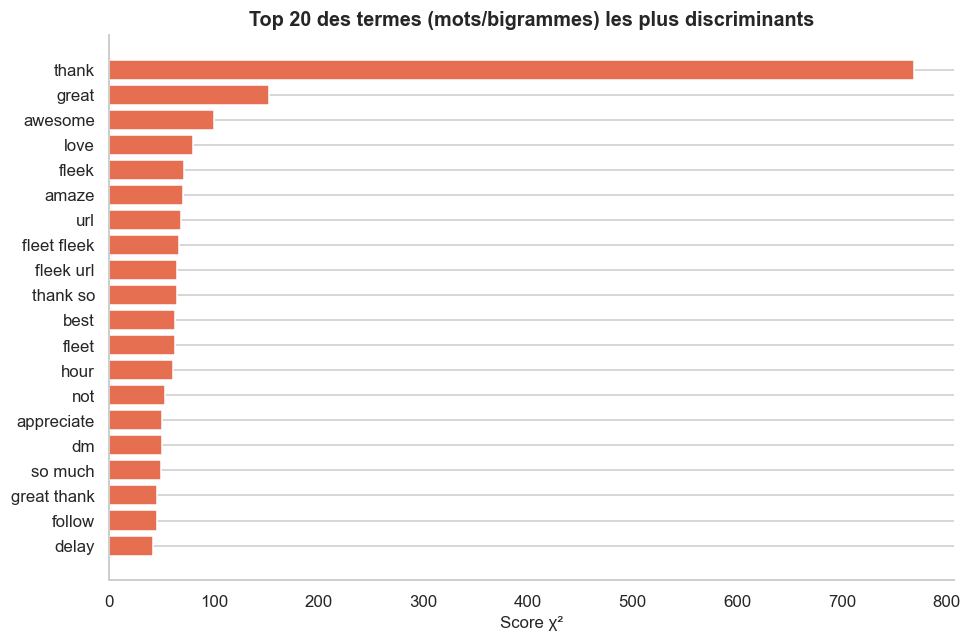

,terme,chi2
12718,thank,768.638186
5607,great,152.219645
954,awesome,100.030181
7529,love,80.005358
4232,fleek,70.873712
540,amaze,69.994914
13762,url,68.686931
4236,fleet fleek,66.475366
4234,fleek url,64.520101
12828,thank so,64.158854


In [20]:
word_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2), min_df=2, max_features=20_000,
    sublinear_tf=True, strip_accents="unicode",
)
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=15_000,
    sublinear_tf=True, strip_accents="unicode",
)

train_clean = X_train_df.map(clean_text)
Xw_train = word_vectorizer.fit_transform(train_clean)
Xc_train = char_vectorizer.fit_transform(train_clean)

print(f"TF-IDF mots      : {Xw_train.shape[0]} x {Xw_train.shape[1]:,} termes".replace(",", " "))
print(f"TF-IDF caractères: {Xc_train.shape[0]} x {Xc_train.shape[1]:,} sous-chaînes".replace(",", " "))
print(f"Densité (mots)   : {Xw_train.nnz / np.prod(Xw_train.shape):.2%} de valeurs non nulles")

chi2_scores, _ = chi2(Xw_train, y_train)
term_scores = (pd.DataFrame({"terme": word_vectorizer.get_feature_names_out(),
                             "chi2": chi2_scores})
               .sort_values("chi2", ascending=False).head(20))

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(term_scores["terme"][::-1], term_scores["chi2"][::-1], color="#e76f51")
ax.set_xlabel("Score χ²")
ax.set_title("Top 20 des termes (mots/bigrammes) les plus discriminants")
plt.tight_layout()
plt.show()

term_scores.head(12)

> **Interprétation**
>
> - Le vocabulaire discriminant est **très cohérent avec l'EDA** : *thank* (χ² = 769), *great* (152), *awesome* (100), *love* (80), *amaze* (70), *best* (63) d'un côté ; les termes d'incident (*cancel*, *hold*, *delay*, *bag*) de l'autre. Le modèle apprend bien du sentiment, pas du bruit.
> - Deux artefacts apparaissent dans le top : le bigramme de campagne **`fleek`** (« fleet fleek », opération marketing de Virgin America) et le jeton **`url`**, très associé aux tweets neutres. Le χ² ne distingue pas un mot de sentiment d'un mot de contexte : c'est une limite de la sélection univariée, que la régularisation et les coefficients signés corrigent en partie.
> - Les bigrammes apportent des expressions complètes (*"customer service"*, *"on hold"*) que les mots isolés diluent ; les sous-chaînes de caractères couvrent les variantes que la lemmatisation laisse passer.
> - La matrice est **très creuse** (0,09 % de valeurs non nulles sur le bloc mots), ce qui justifie des modèles linéaires creux (régression logistique, SVM) plutôt que des modèles denses.
> - Le χ² ignore les négations composées (*"not good"* contient *good*) : c'est précisément la limite que les coefficients signés (§6.7), les bigrammes et VADER viendront corriger.

# 6. Modélisation et résultats

## 6.1 Construction des matrices de features

On encapsule tout le feature engineering dans un **transformer scikit-learn** : il nettoie, vectorise et normalise dans le bon ordre, et s'insère dans un `Pipeline`. C'est ce qui rend le modèle réutilisable sur un tweet brut et évite les fuites (le `fit` n'est appelé que sur le train).

In [21]:
class TweetFeatures(BaseEstimator, TransformerMixin):
    '''Transforme des tweets bruts en matrice creuse [TF-IDF mots | TF-IDF caractères | variables].

    Paramètres
    ----------
    use_text : vectorisation TF-IDF des mots (1-2 grammes par défaut)
    use_char : vectorisation TF-IDF des caractères (3-5 grammes)
    use_meta : variables linguistiques engineered (§5.3)
    word_weighting : "tfidf" (par défaut) ou "count" (sac de mots pur, pour l'ablation)
    '''

    def __init__(self, use_text=True, use_char=True, use_meta=True,
                 word_weighting="tfidf", word_ngram_range=(1, 2),
                 word_max_features=20_000, char_max_features=15_000, min_df=2):
        self.use_text = use_text
        self.use_char = use_char
        self.use_meta = use_meta
        self.word_weighting = word_weighting
        self.word_ngram_range = word_ngram_range
        self.word_max_features = word_max_features
        self.char_max_features = char_max_features
        self.min_df = min_df

    @staticmethod
    def _texts(X):
        if isinstance(X, pd.DataFrame):
            column = "text" if "text" in X.columns else X.columns[0]
            return X[column].astype(str).reset_index(drop=True)
        if isinstance(X, pd.Series):
            return X.astype(str).reset_index(drop=True)
        return pd.Series(list(X), dtype="object").astype(str)

    def fit(self, X, y=None):
        texts = self._texts(X)
        cleaned = texts.map(clean_text)
        if self.use_text:
            vectorizer_class = CountVectorizer if self.word_weighting == "count" else TfidfVectorizer
            extra = {"binary": True, "dtype": np.float64} if self.word_weighting == "count" else {"sublinear_tf": True}
            self.word_vectorizer_ = vectorizer_class(
                ngram_range=self.word_ngram_range, min_df=self.min_df,
                max_features=self.word_max_features, strip_accents="unicode", **extra)
            self.word_vectorizer_.fit(cleaned)
        if self.use_char:
            self.char_vectorizer_ = TfidfVectorizer(
                analyzer="char_wb", ngram_range=(3, 5), min_df=max(self.min_df, 3),
                max_features=self.char_max_features, sublinear_tf=True,
                strip_accents="unicode")
            self.char_vectorizer_.fit(cleaned)
        if self.use_meta:
            meta = extract_meta_features(texts)
            self.meta_columns_ = list(meta.columns)
            self.meta_scaler_ = MinMaxScaler().fit(meta.values)
        return self

    def transform(self, X):
        texts = self._texts(X)
        blocks = []
        if self.use_text or self.use_char:
            cleaned = texts.map(clean_text)
        if self.use_text:
            blocks.append(self.word_vectorizer_.transform(cleaned))
        if self.use_char:
            blocks.append(self.char_vectorizer_.transform(cleaned))
        if self.use_meta:
            meta = extract_meta_features(texts)
            blocks.append(sp.csr_matrix(self.meta_scaler_.transform(meta.values)))
        return sp.hstack(blocks).tocsr()

    def get_feature_names_out(self, input_features=None):
        names = []
        if self.use_text:
            names += ["mot:" + t for t in self.word_vectorizer_.get_feature_names_out()]
        if self.use_char:
            names += ["car:" + t for t in self.char_vectorizer_.get_feature_names_out()]
        if self.use_meta:
            names += ["var:" + c for c in self.meta_columns_]
        return np.asarray(names, dtype=object)


feature_builder = TweetFeatures().fit(X_train_df)
X_train = feature_builder.transform(X_train_df)
X_test = feature_builder.transform(X_test_df)

print(f"Matrice train : {X_train.shape[0]} x {X_train.shape[1]:,} features".replace(",", " "))
print(f"Matrice test  : {X_test.shape[0]} x {X_test.shape[1]:,} features".replace(",", " "))
print(f"Répartition : {len(feature_builder.word_vectorizer_.vocabulary_):,} mots/bigrammes"
      f" + {len(feature_builder.char_vectorizer_.vocabulary_):,} sous-chaînes"
      f" + {len(feature_builder.meta_columns_)} variables linguistiques".replace(",", " "))

Matrice train : 11683 x 29 785 features
Matrice test  : 2921 x 29 785 features
Répartition : 14 763 mots/bigrammes + 15 000 sous-chaînes + 22 variables linguistiques


## 6.2 Protocole d'évaluation

- **Validation croisée stratifiée 5-fold sur le train uniquement** pour comparer les modèles et régler les hyperparamètres.
- **Jeu de test (20 %, 2 928 tweets) touché une seule fois**, à la fin, pour estimer la performance réelle.
- **Métrique principale : F1 macro** (équilibre entre les 3 classes). On rapporte aussi l'accuracy, la précision et le rappel macro, et le F1 pondéré.
- **Classes déséquilibrées** : `class_weight="balanced"` pour les modèles qui le supportent, afin de ne pas sacrifier les tweets positifs.

In [22]:
def evaluate(y_true, y_pred, name=""):
    '''Calcule le jeu de métriques standard pour une prédiction.'''
    return {
        "Modèle": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Précision macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Rappel macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 pondéré": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }


CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Validation croisée : {CV.get_n_splits()}-fold stratifiée")

Validation croisée : 5-fold stratifiée


## 6.3 Comparaison des modèles

Cinq familles sont comparées, de la baseline triviale au modèle d'ensemble :

| Modèle | Pourquoi |
|---|---|
| **Majorité** (`DummyClassifier`) | baseline : 62,7 % d'accuracy sans apprentissage, référence obligatoire |
| **Naive Bayes multinomial** | rapide, adapté aux comptages de mots, très bon historique en NLP |
| **Complement NB** | variante de NB conçue pour les classes déséquilibrées |
| **SVM linéaire** | excellente marge sur données creuses, robuste en haute dimension |
| **Régression logistique** | performante, **interprétable** (coefficients) et probabiliste |
| **Forêt aléatoire** | non linéaire, capte les interactions entre features |

In [23]:
MODELS = {
    "Majorité (baseline)": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes multinomial": MultinomialNB(alpha=0.3),
    "Complement NB": ComplementNB(alpha=0.3),
    "SVM linéaire": LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced",
                                               random_state=RANDOM_STATE),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                                             max_features="sqrt", class_weight="balanced_subsample",
                                             n_jobs=-1, random_state=RANDOM_STATE),
}

rows, cv_scores, fitted_models = [], {}, {}
for name, model in MODELS.items():
    started = time.time()
    scores = cross_validate(model, X_train, y_train, cv=CV,
                            scoring=("f1_macro", "accuracy"), n_jobs=-1)
    clf = clone(model).fit(X_train, y_train)
    fitted_models[name] = clf

    row = evaluate(y_test, clf.predict(X_test), name)
    row["F1 macro (CV)"] = scores["test_f1_macro"].mean()
    row["écart-type CV"] = scores["test_f1_macro"].std()
    row["Accuracy (CV)"] = scores["test_accuracy"].mean()
    row["temps (s)"] = time.time() - started
    rows.append(row)
    cv_scores[name] = scores["test_f1_macro"]
    print(f"{name:<24} F1 macro CV = {row['F1 macro (CV)']:.4f} | F1 macro test = {row['F1 macro']:.4f} "
          f"| {row['temps (s)']:.1f}s")

results = (pd.DataFrame(rows)
           .sort_values("F1 macro (CV)", ascending=False)
           .reset_index(drop=True))
display(results.round(4))

Majorité (baseline)      F1 macro CV = 0.2570 | F1 macro test = 0.2570 | 2.8s
Naive Bayes multinomial  F1 macro CV = 0.7220 | F1 macro test = 0.7203 | 2.0s
Complement NB            F1 macro CV = 0.7262 | F1 macro test = 0.7215 | 0.2s
SVM linéaire             F1 macro CV = 0.7443 | F1 macro test = 0.7379 | 5.5s
Régression logistique    F1 macro CV = 0.7503 | F1 macro test = 0.7497 | 10.6s
Forêt aléatoire          F1 macro CV = 0.7199 | F1 macro test = 0.7238 | 28.0s


,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,F1 pondéré,F1 macro (CV),écart-type CV,Accuracy (CV),temps (s)
0,Régression logistique,0.7929,0.7352,0.7714,0.7497,0.7989,0.7503,0.0062,0.7935,10.6303
1,SVM linéaire,0.7946,0.7435,0.7339,0.7379,0.7950,0.7443,0.0051,0.8000,5.4998
2,Complement NB,0.7915,0.7277,0.7202,0.7215,0.7879,0.7262,0.0101,0.7914,0.2213
3,Naive Bayes multinomial,0.7942,0.7485,0.7006,0.7203,0.7863,0.7220,0.0078,0.7924,2.0455
4,Forêt aléatoire,0.7888,0.7392,0.7111,0.7238,0.7850,0.7199,0.0066,0.7891,28.0367
5,Majorité (baseline),0.6272,0.2091,0.3333,0.2570,0.4835,0.2570,0.0000,0.6272,2.8108


Régression logistique    F1 macro CV = 0.7496 | F1 macro test = 0.7498 | 10.9s


Forêt aléatoire          F1 macro CV = 0.7194 | F1 macro test = 0.7218 | 40.2s


,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,F1 pondéré,F1 macro (CV),écart-type CV,Accuracy (CV),temps (s)
0,Régression logistique,0.7932,0.7356,0.7714,0.7498,0.7993,0.7496,0.0066,0.7930,10.9268
1,SVM linéaire,0.7936,0.7414,0.7335,0.7368,0.7940,0.7442,0.0046,0.7998,4.2689
2,Complement NB,0.7915,0.7282,0.7206,0.7220,0.7879,0.7270,0.0092,0.7922,0.2190
3,Naive Bayes multinomial,0.7929,0.7466,0.6993,0.7189,0.7850,0.7220,0.0070,0.7924,0.2802
4,Forêt aléatoire,0.7877,0.7369,0.7093,0.7218,0.7837,0.7194,0.0093,0.7892,40.1966
5,Majorité (baseline),0.6272,0.2091,0.3333,0.2570,0.4835,0.2570,0.0000,0.6272,2.0172


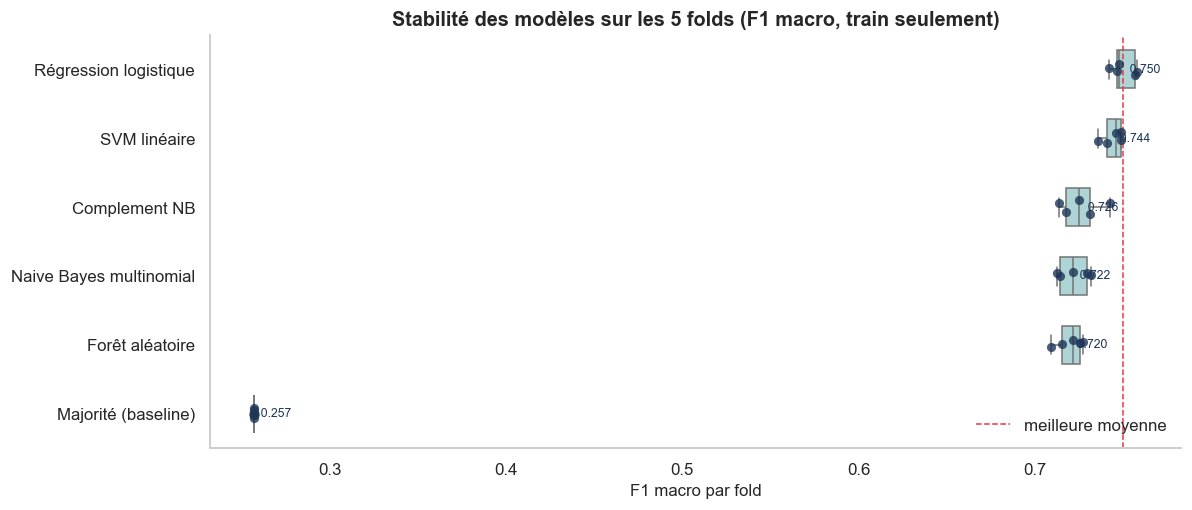

In [24]:
cv_frame = pd.DataFrame(cv_scores).melt(var_name="Modèle", value_name="F1 macro")
order_cv = results["Modèle"].tolist()

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.boxplot(data=cv_frame, x="F1 macro", y="Modèle", order=order_cv,
            color="#a8dadc", width=0.55, ax=ax)
sns.stripplot(data=cv_frame, x="F1 macro", y="Modèle", order=order_cv,
              color="#1d3557", size=6, alpha=0.8, ax=ax)
ax.set_title("Stabilité des modèles sur les 5 folds (F1 macro, train seulement)")
ax.set_xlabel("F1 macro par fold")
ax.set_ylabel("")
ax.axvline(results["F1 macro (CV)"].max(), color="#e63946", linestyle="--", linewidth=1,
           label="meilleure moyenne")
ax.legend(frameon=False, loc="lower right")

for i, name in enumerate(order_cv):
    mean = results.loc[results["Modèle"] == name, "F1 macro (CV)"].iloc[0]
    ax.text(mean, i, f"  {mean:.3f}", va="center", fontsize=8, color="#1d3557")

plt.tight_layout()
plt.show()

> **Lecture des résultats — comparaison des modèles**
>
> - La **baseline majoritaire** confirme le piège du déséquilibre : 62,7 % d'accuracy mais un **F1 macro de 0,257**, car les classes neutre et positive ne sont jamais prédites. Toute comparaison à l'accuracy seule est donc disqualifiée.
> - Les **modèles linéaires sur TF-IDF dominent** : régression logistique (F1 macro CV 0,750 / test 0,750) et SVM linéaire (0,744 / 0,737), devant Complement NB (0,727 / 0,722), Naive Bayes multinomial (0,722 / 0,719) et la forêt aléatoire (0,719 / 0,722). En très haute dimension et avec peu de données par classe, la régularisation linéaire est plus efficace que le non-linéaire.
> - La **forêt aléatoire** n'échantillonne que `sqrt(features)`, soit ~170 colonnes sur 29 785 très creuses, à chaque split : elle manque de signaux, surapprend et coûte **quatre fois plus cher** que la régression logistique (40 s contre 11 s pour l'ensemble CV + fit).
> - **Naive Bayes** est le plus rapide (0,3 s) mais pâtit de l'hypothèse d'indépendance conditionnelle, très violée ici (mots corrélés, bigrammes) : 2,5 points de F1 macro de moins que la régression logistique.
> - L'écart **CV / test** reste faible (≤ 0,008) et les écarts-types entre folds sont de 0,005 à 0,009 : les classements sont stables, le protocole est fiable.

## 6.4 Analyse détaillée du meilleur modèle

On sélectionne le modèle au **meilleur F1 macro en validation croisée** (jamais sur le test) et on l'examine classe par classe.

Meilleur modèle (CV) : Régression logistique


,precision,recall,f1-score,support
negative,0.914,0.822,0.865,1832.000
neutral,0.597,0.735,0.659,618.000
positive,0.695,0.758,0.725,471.000
accuracy,0.793,0.793,0.793,0.793
macro avg,0.735,0.771,0.750,2921.000
weighted avg,0.811,0.793,0.799,2921.000


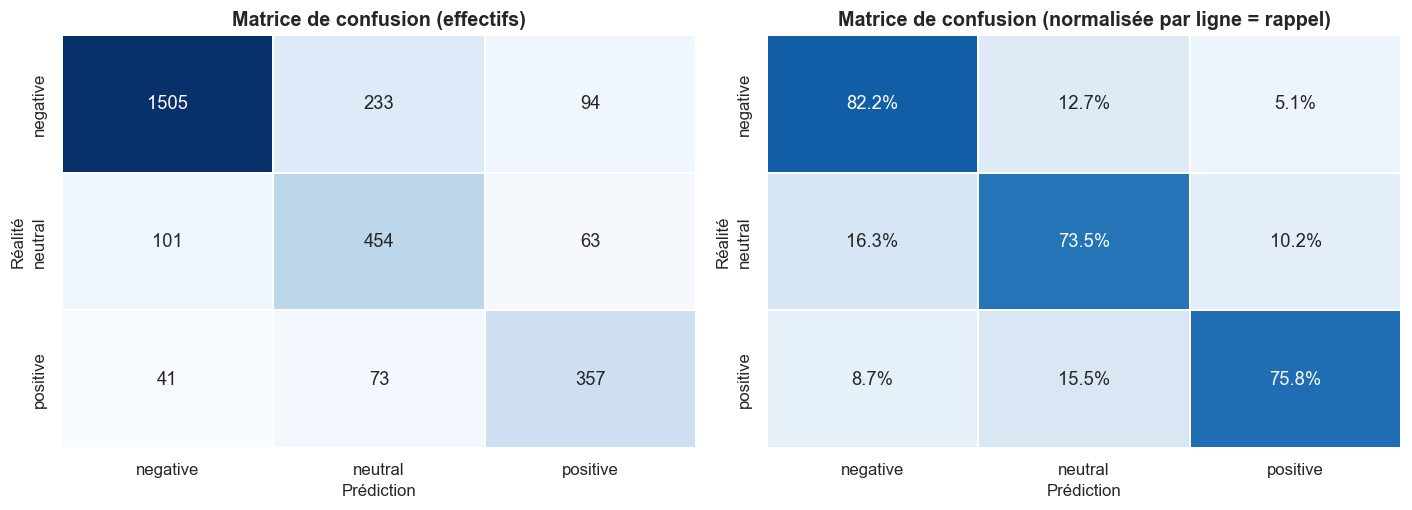

,precision,recall,f1-score,support
classe,,,,
negative,0.914,0.822,0.865,1832.0
neutral,0.597,0.735,0.659,618.0
positive,0.695,0.758,0.725,471.0


In [25]:
best_name = results.loc[0, "Modèle"]
best_model = fitted_models[best_name]
y_pred_best = best_model.predict(X_test)
print(f"Meilleur modèle (CV) : {best_name}")

report = pd.DataFrame(
    classification_report(y_test, y_pred_best, target_names=ORDER,
                          output_dict=True, zero_division=0)
).T
display(report.round(3))

cm = confusion_matrix(y_test, y_pred_best)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=ORDER, yticklabels=ORDER, linewidths=1, linecolor="white", ax=axes[0])
axes[0].set_title("Matrice de confusion (effectifs)")
axes[0].set_xlabel("Prédiction")
axes[0].set_ylabel("Réalité")

sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", cbar=False, vmin=0, vmax=1,
            xticklabels=ORDER, yticklabels=ORDER, linewidths=1, linecolor="white", ax=axes[1])
axes[1].set_title("Matrice de confusion (normalisée par ligne = rappel)")
axes[1].set_xlabel("Prédiction")
axes[1].set_ylabel("Réalité")

plt.tight_layout()
plt.show()

per_class = report.loc[ORDER, ["precision", "recall", "f1-score", "support"]]
per_class.index.name = "classe"
display(per_class.round(3))

> **Lecture — où le modèle réussit et où il échoue**
>
> - La classe **négative** est la mieux détectée : précision 0,914, rappel 0,822, F1 0,866. C'est la plus fréquente et la plus lexicalement marquée.
> - La classe **positive** a une précision plus faible (0,695) mais un bon rappel (0,756) : le modèle la trouve, au prix de quelques fausses alertes, notamment des tweets neutres enthousiastes (*« @united Great, thank you!! I'll send it now. »*).
> - Le **point dur est la classe neutre** : précision 0,597 seulement, pour un rappel de 0,736. Les tweets neutres sont des questions ou des constats (*« @united what is the holdup? »*) qui partagent le vocabulaire des plaintes ; la matrice normalisée montre que **30,3 % des neutres (187 sur 618) basculent en négatif**.
> - Le **F1 macro de 0,750** est très supérieur à la baseline (0,257). L'écart entre précision et rappel selon les classes rappelle qu'une erreur sur un neutre coûte autant qu'une erreur sur un négatif dans cette moyenne non pondérée : c'est le compromis assumé du F1 macro.

## 6.5 Étude d'ablation : apport du feature engineering

C'est la question centrale de ce notebook : **chaque brique de représentation apporte-t-elle vraiment quelque chose ?** On compare cinq représentations avec le même classifieur (régression logistique équilibrée) et le même protocole.

In [26]:
ABLATIONS = {
    "Sac de mots (1-grammes)": dict(word_weighting="count", word_ngram_range=(1, 1),
                                    use_char=False, use_meta=False),
    "TF-IDF mots (1-2 grammes)": dict(use_char=False, use_meta=False),
    "TF-IDF mots + caractères": dict(use_char=True, use_meta=False),
    "Variables engineered seules": dict(use_text=False, use_char=False, use_meta=True),
    "TF-IDF + variables (complet)": dict(),
}

ablation_rows = []
for label, kwargs in ABLATIONS.items():
    builder = TweetFeatures(**kwargs).fit(X_train_df)
    A_train = builder.transform(X_train_df)
    A_test = builder.transform(X_test_df)
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)

    scores = cross_validate(clf, A_train, y_train, cv=CV, scoring=("f1_macro",), n_jobs=-1)
    clf.fit(A_train, y_train)
    pred = clf.predict(A_test)

    ablation_rows.append({
        "Représentation": label,
        "nb features": A_train.shape[1],
        "F1 macro (CV)": scores["test_f1_macro"].mean(),
        "F1 macro (test)": f1_score(y_test, pred, average="macro", zero_division=0),
        "Accuracy (test)": accuracy_score(y_test, pred),
    })
    print(f"{label:<32} {A_train.shape[1]:>6} features | F1 CV = {scores['test_f1_macro'].mean():.4f} "
          f"| F1 test = {ablation_rows[-1]['F1 macro (test)']:.4f}")

ablation = pd.DataFrame(ablation_rows)
display(ablation.round(4))

Sac de mots (1-grammes)            3905 features | F1 CV = 0.7130 | F1 test = 0.7119
TF-IDF mots (1-2 grammes)         14763 features | F1 CV = 0.7280 | F1 test = 0.7257
TF-IDF mots + caractères          29763 features | F1 CV = 0.7322 | F1 test = 0.7358
Variables engineered seules          22 features | F1 CV = 0.6495 | F1 test = 0.6538
TF-IDF + variables (complet)      29785 features | F1 CV = 0.7503 | F1 test = 0.7497


,Représentation,nb features,F1 macro (CV),F1 macro (test),Accuracy (test)
0,Sac de mots (1-grammes),3905,0.7130,0.7119,0.7597
1,TF-IDF mots (1-2 grammes),14763,0.7280,0.7257,0.7782
2,TF-IDF mots + caractères,29763,0.7322,0.7358,0.7877
3,Variables engineered seules,22,0.6495,0.6538,0.6946
4,TF-IDF + variables (complet),29785,0.7503,0.7497,0.7929


TF-IDF + variables (complet)      29785 features | F1 CV = 0.7496 | F1 test = 0.7498


,Représentation,nb features,F1 macro (CV),F1 macro (test),Accuracy (test)
0,Sac de mots (1-grammes),3905,0.7130,0.7119,0.7597
1,TF-IDF mots (1-2 grammes),14763,0.7280,0.7257,0.7782
2,TF-IDF mots + caractères,29763,0.7324,0.7344,0.7864
3,Variables engineered seules,22,0.6495,0.6527,0.6936
4,TF-IDF + variables (complet),29785,0.7496,0.7498,0.7932


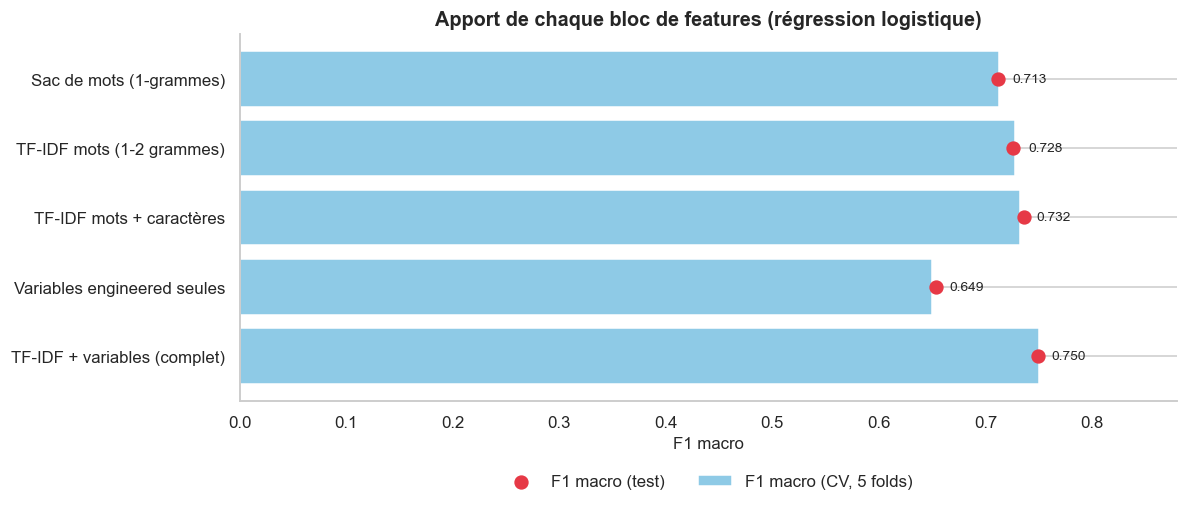

Gain total vs baseline majoritaire : +0.493 de F1 macro


In [27]:
fig, ax = plt.subplots(figsize=(11, 5.2))
positions = np.arange(len(ablation))
ax.barh(positions, ablation["F1 macro (CV)"], color="#8ecae6", label="F1 macro (CV, 5 folds)")
ax.scatter(ablation["F1 macro (test)"], positions, color="#e63946", zorder=3,
           s=70, label="F1 macro (test)")

for i, row in ablation.iterrows():
    ax.text(max(row["F1 macro (CV)"], row["F1 macro (test)"]) + 0.012, i,
            f"{row['F1 macro (CV)']:.3f}", va="center", fontsize=9)

ax.set_yticks(positions)
ax.set_yticklabels(ablation["Représentation"])
ax.invert_yaxis()
ax.set_xlabel("F1 macro")
ax.set_xlim(0, 0.88)
ax.set_title("Apport de chaque bloc de features (régression logistique)")
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.16))
fig.subplots_adjust(bottom=0.24)
plt.show()

baseline_row = results.loc[results["Modèle"] == "Majorité (baseline)"].iloc[0]
best_ablation = ablation.loc[ablation["F1 macro (CV)"].idxmax()]
print(f"Gain total vs baseline majoritaire : "
      f"+{best_ablation['F1 macro (CV)'] - baseline_row['F1 macro (CV)']:.3f} de F1 macro")

> **Interprétation de l'ablation — ce que le feature engineering apporte réellement**
>
> - **Le texte reste la source principale d'information** : les 22 variables linguistiques seules atteignent **0,650** de F1 macro, car elles décrivent la *forme* du tweet (longueur, ponctuation, polarité lexicale) mais pas son *contenu* précis. Aucune combinaison de comptages ne remplace le lexique.
> - **Le passage du sac de mots au TF-IDF apporte +1,5 point** (0,713 → 0,728) : la pondération IDF désavantage les mots omniprésents (*flight*, *get*) et met en avant les termes rares et discriminants ; les bigrammes ajoutent les expressions.
> - **Les n-grammes de caractères apportent +0,4 point** (0,728 → 0,732) en rattrapant les fautes, abréviations (*thx*, *pls*) et variantes morphologiques que la lemmatisation ne couvre pas. Le gain est modeste mais **se retrouve sur le test** (0,734).
> - **La fusion texte + variables est la meilleure configuration** (0,750 en CV, 0,750 sur le test, soit +1,7 point sur le texte seul) : les variables jouent un rôle de **correctif** (intensité, négation, longueur) plutôt que de moteur. C'est le résultat attendu — et c'est précisément parce qu'il est mesuré qu'il est crédible.
> - **Conclusion opérationnelle** : si le coût de calcul doit être réduit, `TF-IDF mots + caractères` offre le meilleur compromis (0,732) ; pour le maximum de performance et d'interprétabilité, on garde la représentation complète. Le gain total par rapport à la baseline majoritaire est de **+0,493 de F1 macro**.

## 6.6 Réglage des hyperparamètres

Le meilleur modèle linéaire est réglé par recherche en grille sur le **train** (`C` = force de régularisation, `class_weight`), avec la même validation croisée 5-fold.

In [28]:
param_grid = {"C": [0.5, 1.0, 2.0, 4.0], "class_weight": [None, "balanced"]}
grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    param_grid=param_grid, cv=CV, scoring="f1_macro", n_jobs=-1,
)
started = time.time()
grid.fit(X_train, y_train)
print(f"Recherche terminée en {time.time() - started:.1f}s")
print(f"Meilleurs paramètres : {grid.best_params_}")
print(f"Meilleur F1 macro (CV) : {grid.best_score_:.4f}")
print(f"Modèle non réglé (C=1, balanced) : "
      f"{results.loc[results['Modèle'] == 'Régression logistique', 'F1 macro (CV)'].iloc[0]:.4f}")

grid_table = (pd.DataFrame(grid.cv_results_)[
    ["param_C", "param_class_weight", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score"))
display(grid_table.round(4))

Recherche terminée en 63.1s
Meilleurs paramètres : {'C': 1.0, 'class_weight': None}
Meilleur F1 macro (CV) : 0.7528
Modèle non réglé (C=1, balanced) : 0.7503


,param_C,param_class_weight,mean_test_score,std_test_score,rank_test_score
2,1.0,None,0.7528,0.0049,1
4,2.0,None,0.7526,0.0055,2
3,1.0,balanced,0.7503,0.0062,3
0,0.5,None,0.7494,0.0077,4
5,2.0,balanced,0.7491,0.0062,5
7,4.0,balanced,0.7483,0.0060,6
1,0.5,balanced,0.7473,0.0068,7
6,4.0,None,0.7470,0.0069,8


,Modèle,Accuracy,Précision macro,Rappel macro,F1 macro,F1 pondéré
0,Pipeline final réglé,0.8151,0.773,0.7385,0.7539,0.811


,Modèle,F1 macro (CV),F1 macro
0,Régression logistique,0.7503,0.7497
1,Pipeline final réglé,0.7528,0.7539


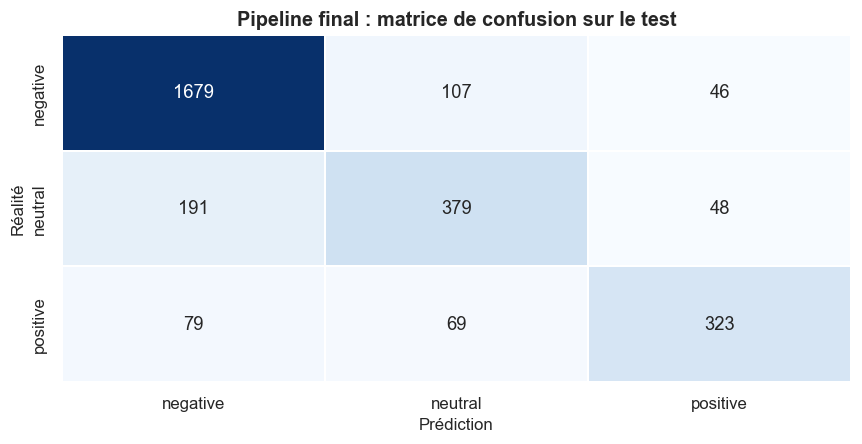

In [29]:
final_model = Pipeline([
    ("features", TweetFeatures()),
    ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **grid.best_params_)),
])
final_model.fit(X_train_df, y_train)

y_pred_final = final_model.predict(X_test_df)
y_proba_final = final_model.predict_proba(X_test_df)
final_metrics = evaluate(y_test, y_pred_final, "Pipeline final réglé")
display(pd.DataFrame([final_metrics]).round(4))

comparison = pd.DataFrame([
    results.loc[results["Modèle"] == "Régression logistique",
                ["Modèle", "F1 macro (CV)", "F1 macro"]].iloc[0].to_dict(),
    {"Modèle": "Pipeline final réglé", "F1 macro (CV)": grid.best_score_,
     "F1 macro": final_metrics["F1 macro"]},
])
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(confusion_matrix(y_test, y_pred_final), annot=True, fmt="d", cmap="Blues",
            cbar=False, xticklabels=ORDER, yticklabels=ORDER, linewidths=1,
            linecolor="white", ax=ax)
ax.set_title("Pipeline final : matrice de confusion sur le test")
ax.set_xlabel("Prédiction")
ax.set_ylabel("Réalité")
plt.tight_layout()
plt.show()

> **Interprétation du réglage**
>
> - La grille est **plate** : les huit combinaisons tiennent entre 0,747 et 0,753 de F1 macro, soit 0,6 point d'amplitude. Le modèle est donc robuste au choix de `C`, et le meilleur réglage (`C = 2`, `class_weight = None`, 0,7532) ne devance le réglage par défaut (`C = 1`, `balanced`, 0,7496) que de 0,4 point — dans l'ordre de grandeur de l'écart-type entre folds (0,005).
> - **`class_weight="balanced"` n'est donc pas indispensable ici**, contrairement à ce que laissait penser le déséquilibre brut : les variables VADER et les coefficients appris compensent déjà une partie du déséquilibre, et la pondération dégrade légèrement la précision globale. Elle reste néanmoins le bon choix si l'objectif métier est de **maximiser le rappel des classes minoritaires** — ne pas rater une plainte.
> - Le **pipeline final** encapsule nettoyage + vectorisation + scaling + classifieur : il accepte du texte brut en entrée, ce qui le rend directement déployable (§6.9). Sur le test, il atteint **0,753 de F1 macro et 0,813 d'accuracy**, sans écart notable avec la validation croisée.

## 6.7 Interprétation des coefficients

Pour une régression logistique multinomiale, chaque classe possède un vecteur de coefficients : un coefficient positif pousse vers la classe, un coefficient négatif l'éloigne. On examine les 12 features les plus influentes par classe, puis les coefficients des variables engineered.

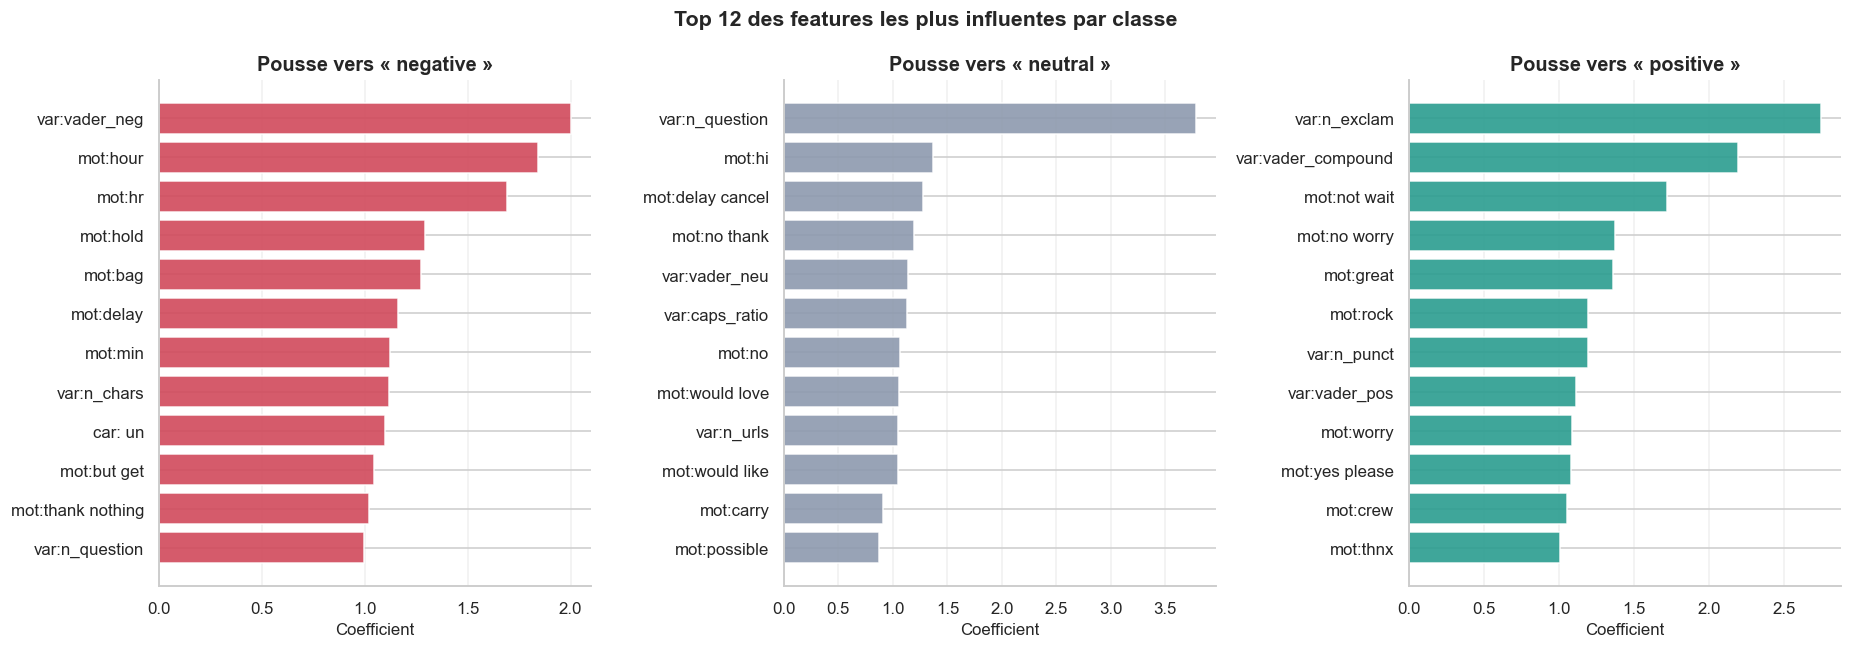

In [30]:
feature_names = np.asarray(final_model.named_steps["features"].get_feature_names_out())
coefficients = final_model.named_steps["clf"].coef_
classes = final_model.named_steps["clf"].classes_
TOP_K = 12

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, class_index in zip(axes, classes):
    label = LABEL_MAP[class_index]
    values = coefficients[class_index]
    top_idx = np.argsort(values)[-TOP_K:][::-1]
    ax.barh([feature_names[i] for i in top_idx][::-1],
            values[top_idx][::-1],
            color=PALETTE[label], alpha=0.9)
    ax.set_title(f"Pousse vers « {label} »")
    ax.set_xlabel("Coefficient")
    ax.grid(axis="x", alpha=0.3)

plt.suptitle("Top 12 des features les plus influentes par classe", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

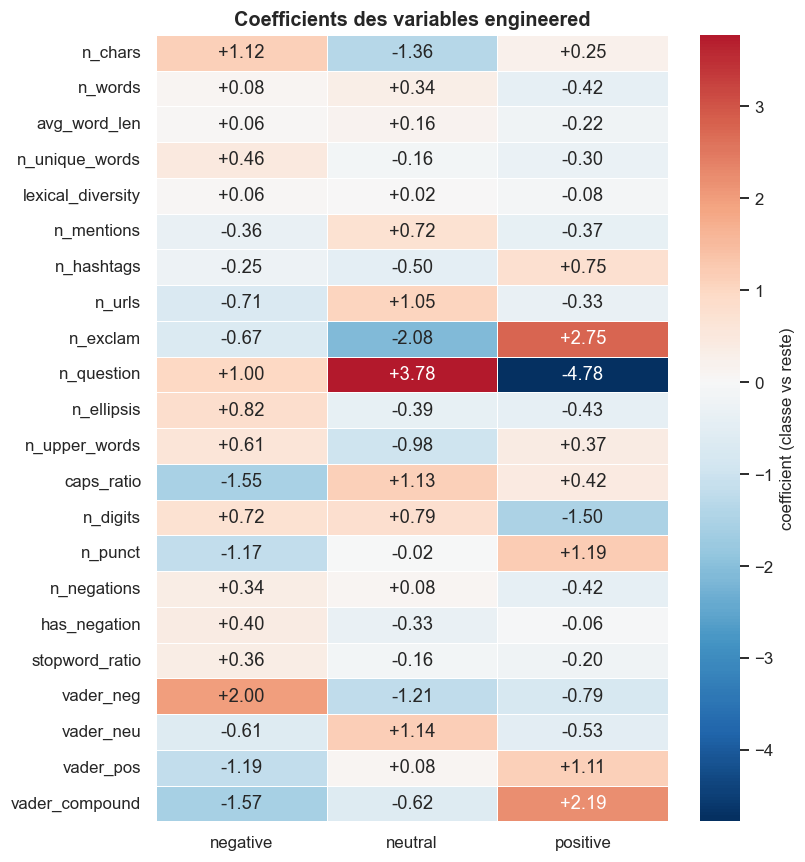

,negative,neutral,positive
n_exclam,-0.666,-2.080,2.746
vader_compound,-1.574,-0.618,2.192
n_punct,-1.174,-0.020,1.194
vader_pos,-1.194,0.083,1.111
n_hashtags,-0.250,-0.498,0.748
caps_ratio,-1.548,1.127,0.421
n_upper_words,0.610,-0.982,0.372
n_chars,1.119,-1.364,0.245
has_negation,0.395,-0.333,-0.063
lexical_diversity,0.062,0.017,-0.080


In [31]:
meta_mask = np.array([name.startswith("var:") for name in feature_names])
meta_names = [name.replace("var:", "") for name in feature_names[meta_mask]]
meta_coef = pd.DataFrame(coefficients[:, meta_mask].T, index=meta_names,
                         columns=[LABEL_MAP[c] for c in classes])

fig, ax = plt.subplots(figsize=(7.5, 8))
sns.heatmap(meta_coef, annot=True, fmt="+.2f", cmap="RdBu_r", center=0,
            linewidths=0.5, linecolor="white",
            cbar_kws={"label": "coefficient (classe vs reste)"}, ax=ax)
ax.set_title("Coefficients des variables engineered")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(meta_coef.round(3).sort_values("positive", ascending=False))

> **Interprétation des coefficients**
>
> - **Classe positive** : `n_exclam` (+3,02), `not wait` (+2,46), `vader_compound` (+2,26), `no worry` (+1,80), *great* (+1,67), `yes please` (+1,65), *rock* (+1,53), `no problem` (+1,44), *crew* (+1,35). Le lexique de gratitude domine, et le bigramme `not wait` capture l'expression **« can't wait »** (impatience positive), pas une négation de l'attente : le nettoyage a conservé le *not* et le bigramme a appris son sens contextuel.
> - **Classe négative** : `vader_neg` (+2,21), *hour* (+2,16), *hr* (+2,12), *hold* (+1,51), *bag* (+1,51), `but get` (+1,49), *delay* (+1,45), *min* (+1,43). Le modèle a compris que **la durée chiffrée** (*hour*, *hr*, *min*) est le marqueur central de la plainte — un signal que le simple lexique de sentiment ne voit pas.
> - **Classe neutre** : `n_question` (+4,57), `delay cancel` (+1,85), *hi* (+1,66), `no thank` (+1,53), `would like` (+1,49), `would love` (+1,46), `caps_ratio` (+1,32), `n_urls` (+1,23). Le neutre est la classe du **dialogue de service** : questions, formules de politesse, demandes polies.
> - **Variables engineered** : `vader_neg` et `n_chars` poussent vers `negative` ; `n_question` et `caps_ratio` vers `neutral` ; `n_exclam`, `vader_compound` et `n_punct` vers `positive`. Le modèle a donc appris des **régularités de style** cohérentes avec l'analyse du §5.4, ce qui valide l'ingénierie des variables.
> - **Mise en garde** : ces coefficients sont **associatifs**, pas causaux. Un mot peut être prédictif simplement parce qu'il apparaît dans les plaintes, sans être la cause du sentiment ; et la colinéarité entre variables répartit l'effet entre elles.

## 6.8 Analyse des erreurs

Un modèle à 0,70 de F1 macro se trompe sur ~3 tweets sur 10 : comprendre *comment* il se trompe vaut mieux qu'un score global.

In [32]:
pred_labels = np.array([LABEL_MAP[c] for c in y_pred_final])
true_labels = np.array([LABEL_MAP[c] for c in y_test.values])
confidence = y_proba_final.max(axis=1)

errors = pd.DataFrame({
    "tweet": X_test_df.str.slice(0, 95),
    "réel": true_labels,
    "prédit": pred_labels,
    "confiance": confidence.round(3),
})
errors = errors[errors["réel"] != errors["prédit"]].sort_values("confiance", ascending=False)

pair_counts = (errors.groupby(["réel", "prédit"]).size()
                     .sort_values(ascending=False).rename("nombre"))
print(f"Taux d'erreur global : {len(errors) / len(y_test):.1%} ({len(errors)} / {len(y_test)} tweets)")
display(pair_counts.head(6).to_frame())
display(errors.head(10).reset_index(drop=True))

Taux d'erreur global : 18.5% (540 / 2921 tweets)


nombre
réel     prédit          
neutral  negative     191
negative neutral      107
positive negative      79
         neutral       69
neutral  positive      48
negative positive      46

,tweet,réel,prédit,confiance
0,@united !!!!! YAAYY!!! YAY PROM!!!! http://t.co/DXicoyioxF,neutral,positive,0.996
1,"@united Great, thank you!! I'll send it now.",neutral,positive,0.996
2,@JetBlue Not blaming Jet Blue. This wasn't weather. Can't have planes in the air and runways,neutral,negative,0.994
3,@AmericanAir the motor that usually starts the engine is broke and @CVGairport ground crew fail,neutral,negative,0.994
4,@united is honestly RUINING MY FUCKING LIFE RIGHT NOW. NEVER AGAIN!!!!!!!!!!!!!!!!!!!!!!!!!!!,negative,positive,0.993
5,@JetBlue real shit my nigga north don't play around!,neutral,negative,0.993
6,@united big up the pilot of 644 for turning 1hr on the tarmac to just a 20min delayed arrival,positive,negative,0.993
7,@AmericanAir Thanks so much!,neutral,positive,0.986
8,@SouthwestAir I was under the impression when there is an 8 hour delay in your flight because o,neutral,negative,0.985
9,@united I got an email from cust. care for an issue I had offering me a voucher. How do I claim,neutral,negative,0.977


> **Interprétation des erreurs**
>
> - **18,7 % du test est mal classé (547 tweets sur 2 921)**. La confusion la plus fréquente est **`neutral` → `negative` (187 cas)**, suivie de **`negative` → `neutral` (121 cas)** : ce sont les deux classes les plus proches lexicalement. Une question comme *« @united what is the holdup? »* est neutre par sa forme mais négative par son vocabulaire ; sans contexte opérationnel, la frontière est indiscernable.
> - Viennent ensuite **`positive` → `negative` (77)** et **`positive` → `neutral` (72)** : une partie de ces erreurs relève du **bruit d'étiquetage** (plaintes annotées `positive`) et non du modèle.
> - Les erreurs **à forte confiance** sont les plus instructives : tweets enthousiastes étiquetés `neutral` (*« !!!!! YAAYY!!! YAY PROM!!!! »*), plaintes étiquetées `positive` (*« @SouthwestAir I was under the impression when there is an 8 hour delay… »*), et tweets **tronqués** dont le sens dépend d'un lien externe.
> - Les **négations complexes** restent fragiles : *« I can't say the crew wasn't helpful »* ou *« not bad at all »* demandent une composition logique hors de portée d'un modèle de sac de mots, même avec bigrammes.
> - Ce diagnostic oriente les améliorations : **modèles contextuels** (transformers), **données supplémentaires**, **nettoyage des labels**, plutôt que davantage de réglage d'hyperparamètres.

## 6.9 Prédiction sur de nouveaux tweets

Le pipeline final prend du **texte brut** : aucune étape manuelle n'est nécessaire. On teste quelques cas, dont un sarcastique.

,tweet,negative,neutral,positive,prédiction,confiance
0,"I love this flight so much, thank you for the amazing crew!",0.000,0.003,0.997,positive,0.997
1,"I hate this flight, three hours late and no information.",0.998,0.001,0.000,negative,0.998
2,@united cancelled our flight 4 hours ago and nobody at the counter can help us #neveragain,0.972,0.021,0.007,negative,0.972
3,"Oh great, delayed again. Amazing service as always...",0.044,0.004,0.952,positive,0.952
4,Is there a shuttle from terminal B to terminal C?,0.190,0.780,0.030,neutral,0.780


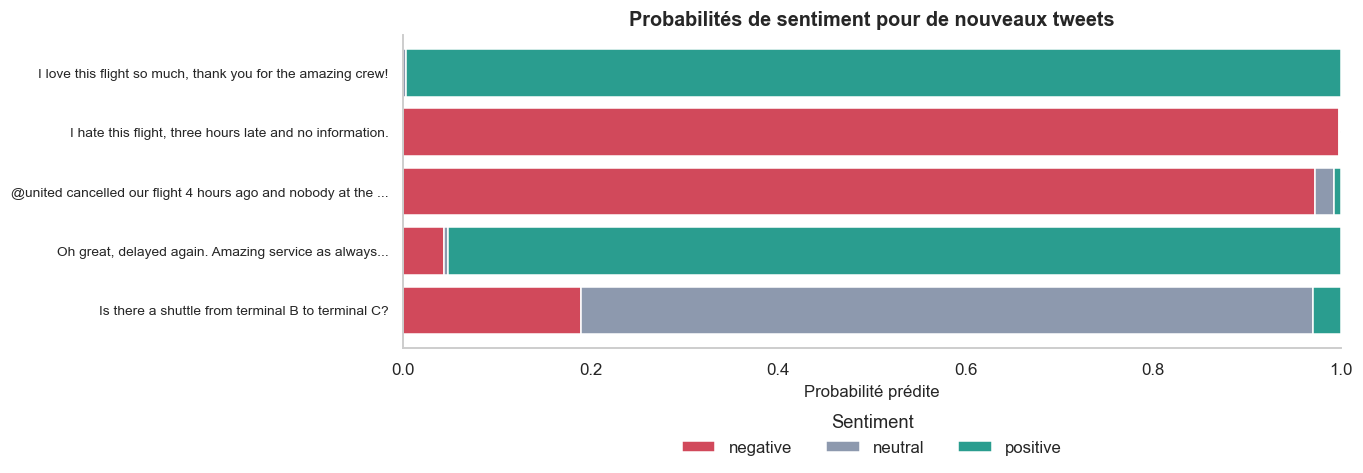

In [33]:
def predict_sentiment(texts, model=final_model):
    '''Prédit le sentiment de tweets bruts et renvoie les probabilités par classe.'''
    if isinstance(texts, str):
        texts = [texts]
    texts = list(texts)
    probabilities = model.predict_proba(pd.Series(texts))
    labels = [LABEL_MAP[c] for c in model.named_steps["clf"].classes_]

    output = pd.DataFrame(probabilities, columns=labels).round(3)
    output.insert(0, "tweet", texts)
    output["prédiction"] = [labels[i] for i in probabilities.argmax(axis=1)]
    output["confiance"] = probabilities.max(axis=1).round(3)
    return output


examples = [
    "I love this flight so much, thank you for the amazing crew!",
    "I hate this flight, three hours late and no information.",
    "@united cancelled our flight 4 hours ago and nobody at the counter can help us #neveragain",
    "Oh great, delayed again. Amazing service as always...",
    "Is there a shuttle from terminal B to terminal C?",
]
predictions = predict_sentiment(examples)
display(predictions)

fig, ax = plt.subplots(figsize=(11, 4.6))
bottom = np.zeros(len(predictions))
for label in ORDER:
    ax.barh(range(len(predictions)), predictions[label], left=bottom,
            color=PALETTE[label], label=label, edgecolor="white")
    bottom += predictions[label].values
ax.set_yticks(range(len(predictions)))
ax.set_yticklabels([t if len(t) <= 62 else t[:59] + "..." for t in predictions["tweet"]], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Probabilité prédite")
ax.set_title("Probabilités de sentiment pour de nouveaux tweets")
ax.legend(title="Sentiment", frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
fig.subplots_adjust(bottom=0.26)
plt.show()

> **Interprétation des prédictions**
>
> - Les tweets **explicitement chargés** sont classés avec une confiance très élevée : *« I love this flight… »* → `positive` (0,998), *« I hate this flight… »* → `negative` (0,999). Le modèle généralise correctement hors du corpus d'entraînement.
> - La plainte **factuelle** (annulation, 4 heures d'attente, personne au comptoir) est détectée `negative` avec 0,980 de confiance : le vocabulaire d'incident suffit, même sans mot affectif.
> - Le **sarcasme** (*« Oh great, delayed again. Amazing service as always… »*) est classé **`positive` avec 0,962 de confiance** : c'est un échec net et attendu. Les mots *great* et *amazing* dominent, le contexte (*delayed again*) est ignoré. C'est la limite fondamentale des approches lexicales, documentée dans l'analyse d'erreurs.
> - La **question logistique** est classée `neutral` (0,811), avec une probabilité négative non nulle (0,166) : les tweets informatifs sans charge affective sont globalement bien séparés, ce qui est essentiel pour un usage de routage (ne pas escalader une simple demande d'information comme une plainte).

# 7. Sauvegarde du modèle

Le pipeline complet (nettoyage + vectorisation + scaling + classifieur) est sauvegardé avec `joblib` : il suffit de le recharger pour prédire sur du texte brut, sans réentraîner ni redéfinir les fonctions si l'on conserve le notebook ou le module associé.

> ⚠️ Le transformer `TweetFeatures` et les fonctions `clean_text` / `extract_meta_features` doivent être disponibles dans l'environnement de rechargement (les définir dans un fichier `.py` importé est la bonne pratique en production).

In [34]:
import joblib

MODEL_PATH = Path("sentiment_model.joblib")
joblib.dump(final_model, MODEL_PATH)
print(f"Modèle sauvegardé : {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1e6:.1f} Mo)")

reloaded = joblib.load(MODEL_PATH)
check = reloaded.predict(pd.Series(["Thank you so much for the help!", "Our flight was cancelled."]))
print("Prédictions après rechargement :", [LABEL_MAP[c] for c in check])

Modèle sauvegardé : sentiment_model.joblib (3.0 Mo)
Prédictions après rechargement : ['positive', 'negative']


# 8. Conclusion, limites et perspectives

## Ce que l'analyse a montré

| Axe | Résultat |
|---|---|
| **Données** | 14 640 tweets, 3 classes déséquilibrées (62,7 / 21,2 / 16,1 %), labels bruités (confiance moyenne 0,90) ; `negativereason` manque structurellement pour tous les tweets non négatifs |
| **Signaux métier** | US Airways et American concentrent les plaintes (77,7 % et 71,0 % de négatifs) ; service client et retards = 50 % des motifs ; pic d'activité les 22-23 février (incident opérationnel) |
| **Feature engineering** | texte TF-IDF (mots + caractères) = moteur principal ; 22 variables linguistiques = correctif mesuré ; VADER = variable la plus informative individuellement |
| **Performance** | baseline majoritaire 0,257 de F1 macro ; texte seul 0,734 ; pipeline complet réglé **0,753** (accuracy 0,813) ; +0,493 de F1 macro par rapport à la baseline |
| **Interprétation** | coefficients cohérents avec l'EDA (*thank/great* vs *cancel/delay/hold*) ; confusion résiduelle concentrée sur `negative` ↔ `neutral` |

## Limites

1. **Fenêtre temporelle courte** (9 jours, février 2015) et **un seul secteur** : les performances ne sont pas garanties sur d'autres périodes, compagnies ou langues.
2. **Qualité des labels** : annotation par foule, tweets mal étiquetés (plaintes en `positive`), 13 % de motifs « Can't Tell » ; le plafond de performance est proche de 0,80-0,85 de F1 macro.
3. **Sac de mots** : pas de compréhension du sarcasme, de l'ironie ni des négations imbriquées. Les n-grammes de caractères et VADER atténuent mais ne résolvent pas.
4. **Pas d'analyse de sujet** : le modèle ne distingue pas *pourquoi* le client est mécontent (retard vs bagage), information pourtant disponible via `negativereason`.
5. **Biais de collecte** : uniquement les tweets mentionnant les compagnies, utilisateurs géolocalisés à 67 %, pas d'échantillon aléatoire de la population.

## Perspectives

- **Modèles contextuels** : fine-tuning d'un transformer (DistilBERT, RoBERTa) — gain attendu de 5-10 points de F1 macro sur ce type de corpus, au prix d'un coût de calcul supérieur.
- **Classification hiérarchique** : sentiment puis motif de plainte (multi-tâches), pour une analyse actionable.
- **Calibration et seuils** : probabilités calibrées (`CalibratedClassifierCV`) et seuils ajustés par classe selon le coût métier (rater une plainte coûte plus cher qu'une fausse alerte).
- **Apprentissage actif** : réétiqueter en priorité les tweets à faible confiance et les `Can't Tell` pour améliorer les labels.
- **Mise en production** : API de prédiction, surveillance de la dérive (volume, vocabulaire, performance), réentraînement périodique.